## Table of Contents
* [1. Data Loading & Basic Checks](#1-data-loading--basic-checks)
  * [Table Previews](#table-previews)
* [2. Missing Values & Time-Series Cleaning](#2-missing-values--time-series-cleaning)
  * [2.1 Checking Calendar Completeness & Inserting Missing Christmas Dates](#21-checking-calendar-completeness--inserting-missing-christmas-dates)
  * [2.2 Filling Non-Holiday Dates (`holiday_name`)](#22-filling-non-holiday-dates-holiday_name)
  * [2.3 Imputing Missing Oil Prices (`oil_price`)](#23-imputing-missing-oil-prices-oil_price)
  * [2.4 Final Missing Values Check](#24-final-missing-values-check)
* [3. Exploratory Data Analysis (EDA) & Domain Insights](#3-exploratory-data-analysis-eda--domain-insights)
  * [3.1 Total Daily Sales over Time (Daily vs. 7-Day Trend)](#31-total-daily-sales-over-time-daily-vs-7-day-trend)
  * [3.2 Product Family & Store Scale](#32-product-family--store-scale)
  * [3.3 Average Sales per Day of Month (Payday Effect)](#33-average-sales-per-day-of-month-payday-effect)
  * [3.4 Average Sales per Weekday (Weekend Effect)](#34-average-sales-per-weekday-weekend-effect)
  * [3.5 Oil Price & Macroeconomic Momentum vs. Sales](#35-oil-price--macroeconomic-momentum-vs-sales)
  * [3.6 Promotions vs. Sales](#36-promotions-vs-sales)
  * [3.7 Store Transactions vs. Sales](#37-store-transactions-vs-sales)
  * [3.8 Target Distribution (RMSLE) & Lagged Sales Autocorrelation](#38-target-distribution-rmsle--lagged-sales-autocorrelation)
* [4. Feature Engineering Pipeline](#4-feature-engineering-pipeline)
  * [4.1 Exporting Processed Feature Matrices](#41-exporting-processed-feature-matrices)

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import db_dtypes
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import Markdown, display
import gc

pd.set_option('display.max_columns', None)

# Dynamically resolve the data directory regardless of the active working directory
cwd = Path.cwd()
if (cwd / "data").exists():
    DATA_DIR = cwd / "data"
elif (cwd.parent / "data").exists():
    DATA_DIR = cwd.parent / "data"
else:
    DATA_DIR = cwd / "store-sales-forecasting" / "data"

print(f"Active Data Directory: {DATA_DIR.resolve()}")

Active Data Directory: /home/user/myprojects/store-sales-forecasting/data


# 1. Data Loading & Basic Checks
Load the extracted Parquet tables from `data/interim/`, convert the `date` column to standard pandas datetime, and sort the rows chronologically. Since BigQuery exports data from distributed workers, sorting by `(store_nbr, family, date)` is essential before running any time-series operations.

In [2]:
df_train = pd.read_parquet(DATA_DIR / 'interim/train.parquet')
df_test = pd.read_parquet(DATA_DIR / 'interim/test.parquet')
df_transactions = pd.read_parquet(DATA_DIR / 'interim/transactions.parquet')

for df in [df_train, df_test, df_transactions]:
    df['date'] = pd.to_datetime(df['date'])

df_train = df_train.sort_values(by=['store_nbr', 'family', 'date']).reset_index(drop=True)
df_test = df_test.sort_values(by=['store_nbr', 'family', 'date']).reset_index(drop=True)
df_transactions = df_transactions.sort_values(by=['store_nbr', 'date']).reset_index(drop=True)

print('TRAIN.PARQUET DTYPES:', df_train.dtypes, sep='\n', end='\n\n')
display(Markdown('---'))
print('TEST.PARQUET DTYPES:', df_test.dtypes, sep='\n', end='\n\n')
display(Markdown('---'))
print('TRANSACTIONS.PARQUET DTYPES:', df_transactions.dtypes, sep='\n', end='\n\n')

TRAIN.PARQUET DTYPES:
id                      Int64
date            datetime64[s]
store_nbr               Int64
family                    str
onpromotion             Int64
city                      str
state                     str
store_type                str
cluster                 Int64
oil_price             float64
sales                 float64
is_holiday            boolean
holiday_name              str
dtype: object



---

TEST.PARQUET DTYPES:
id                      Int64
date            datetime64[s]
store_nbr               Int64
family                    str
onpromotion             Int64
city                      str
state                     str
store_type                str
cluster                 Int64
oil_price             float64
is_holiday            boolean
holiday_name              str
dtype: object



---

TRANSACTIONS.PARQUET DTYPES:
date            datetime64[s]
store_nbr               Int64
transactions            Int64
dtype: object



### Table Previews
Inspect each table to confirm the date ranges and sorting order.

In [3]:
print('TRAIN.PARQUET PREVIEW:')
display(df_train)
display(Markdown('---'))
print('TEST.PARQUET PREVIEW:')
display(df_test)
display(Markdown('---'))
print('TRANSACTIONS.PARQUET PREVIEW:')
display(df_transactions)

TRAIN.PARQUET PREVIEW:


,id,date,store_nbr,family,onpromotion,city,state,store_type,cluster,oil_price,sales,is_holiday,holiday_name
0,0,2013-01-01,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,NaN,0.0,True,Primer dia del ano
1,1782,2013-01-02,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,93.14,2.0,False,NaN
2,3564,2013-01-03,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,92.97,3.0,False,NaN
3,5346,2013-01-04,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,93.12,3.0,False,NaN
4,7128,2013-01-05,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,NaN,5.0,False,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3000883,2993627,2017-08-11,54,SEAFOOD,0,El Carmen,Manabi,C,3,48.81,0.0,True,Traslado Primer Grito de Independencia
3000884,2995409,2017-08-12,54,SEAFOOD,1,El Carmen,Manabi,C,3,NaN,1.0,False,NaN
3000885,2997191,2017-08-13,54,SEAFOOD,0,El Carmen,Manabi,C,3,NaN,2.0,False,NaN
3000886,2998973,2017-08-14,54,SEAFOOD,0,El Carmen,Manabi,C,3,47.59,0.0,False,NaN


---

TEST.PARQUET PREVIEW:


,id,date,store_nbr,family,onpromotion,city,state,store_type,cluster,oil_price,is_holiday,holiday_name
0,3000888,2017-08-16,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,46.80,False,NaN
1,3002670,2017-08-17,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,47.07,False,NaN
2,3004452,2017-08-18,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,48.59,False,NaN
3,3006234,2017-08-19,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,NaN,False,NaN
4,3008016,2017-08-20,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,NaN,False,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
28507,3022139,2017-08-27,54,SEAFOOD,0,El Carmen,Manabi,C,3,NaN,False,NaN
28508,3023921,2017-08-28,54,SEAFOOD,0,El Carmen,Manabi,C,3,46.40,False,NaN
28509,3025703,2017-08-29,54,SEAFOOD,0,El Carmen,Manabi,C,3,46.46,False,NaN
28510,3027485,2017-08-30,54,SEAFOOD,0,El Carmen,Manabi,C,3,45.96,False,NaN


---

TRANSACTIONS.PARQUET PREVIEW:


,date,store_nbr,transactions
0,2013-01-02,1,2111
1,2013-01-03,1,1833
2,2013-01-04,1,1863
3,2013-01-05,1,1509
4,2013-01-06,1,520
...,...,...,...
83483,2017-08-11,54,768
83484,2017-08-12,54,903
83485,2017-08-13,54,1054
83486,2017-08-14,54,818


# 2. Missing Values & Time-Series Cleaning
Before building features, we need to ensure our calendar timeline has no missing dates and handle missing values in `holiday_name` and `oil_price` so the dataset is complete and ready for modeling.

In [4]:
def print_perc_of_nans(df, col_names, name="DF"):
    for col_name in col_names:
        nans = df[col_name].isna().sum()
        total = len(df)
        perc = (nans * 100.0) / total
        print(f'{name} - {col_name}: {nans:,} NaNs out of {total:,} ({perc:.1f}%)', end='\n')

### 2.1 Checking Calendar Completeness & Inserting Missing Christmas Dates
A complete daily timeline from `2013-01-01` to `2017-08-15` spans **1,688 calendar days**. Across 54 stores and 33 product families ($54 \times 33 = 1,782$ series), `df_train` should contain $1,688 \times 1,782 = 3,008,016$ rows, but it only has $3,000,888$ rows: a deficit of **7,128 rows** (exactly 4 full days).

Below, we verify that all 54 stores and 33 families are present on every recorded date, identify the 4 missing dates (Christmas Day, Dec 25, for 2013–2016 when stores were closed), and insert them with `sales = 0`. Filling these calendar gaps ensures that row-based time-series shifts (such as `.shift(21)`) align with date-based time-series shifts.

In [5]:
# Expected vs. actual dimensions
full_train_calendar = pd.date_range(start='2013-01-01', end='2017-08-15', freq='D')
n_expected_days = len(full_train_calendar)
n_stores = df_train['store_nbr'].nunique()
n_families = df_train['family'].nunique()
expected_rows = n_expected_days * n_stores * n_families
missing_rows = expected_rows - len(df_train)

print(f"Expected calendar days (2013-01-01 to 2017-08-15): {n_expected_days}")
print(f"Unique stores: {n_stores} | Unique families: {n_families} (Series per day: {n_stores * n_families})")
print(f"Expected rows: {expected_rows:,} | Actual rows: {len(df_train):,}")
print(f"Missing rows:  {missing_rows:,} ({missing_rows // (n_stores * n_families)} full days)\n")

# Check if any recorded date is missing a store or family, and find the missing dates
rows_per_date = df_train.groupby('date').size()
incomplete_dates = rows_per_date[rows_per_date != (n_stores * n_families)]
print(f"Recorded dates with incomplete store-family pairs: {len(incomplete_dates)}")

missing_dates = full_train_calendar.difference(df_train['date'].unique())
print(f"Missing calendar dates: {[str(d.date()) for d in missing_dates]}\n")

# Build and insert the missing Christmas Day rows using exact store metadata
store_family_meta = (
    df_train[['store_nbr', 'family', 'city', 'state', 'store_type', 'cluster']]
    .drop_duplicates()
    .sort_values(by=['store_nbr', 'family'])
    .reset_index(drop=True)
)

christmas_df = (
    pd.DataFrame({'date': missing_dates})
    .merge(store_family_meta, how='cross')
    .assign(
        id=-1,                   # Placeholder ID (dropped before modeling)
        onpromotion=0,           # No active promotions on store closures
        oil_price=np.nan,        # Imputed via ffill() in Section 2.3
        sales=0.0,               # Stores are closed on Christmas Day
        is_holiday=1,            # National holiday flag
        holiday_name='Navidad',  # Official holiday name in Favorita metadata
    )[df_train.columns]          # Preserve exact column order
    .astype(df_train.dtypes.to_dict())  # Preserve exact BigQuery/Parquet dtypes (Int64, etc.)
)

df_train = (
    pd.concat([df_train, christmas_df], ignore_index=True)
    .sort_values(by=['store_nbr', 'family', 'date'])
    .reset_index(drop=True)
)

print(f"Updated df_train shape: {df_train.shape[0]:,} rows x {df_train.shape[1]} cols (Unique days: {df_train['date'].nunique()})")

display(df_train.loc[(df_train['date'].dt.month==12) & (df_train['date'].dt.day==25)])

Expected calendar days (2013-01-01 to 2017-08-15): 1688
Unique stores: 54 | Unique families: 33 (Series per day: 1782)
Expected rows: 3,008,016 | Actual rows: 3,000,888
Missing rows:  7,128 (4 full days)

Recorded dates with incomplete store-family pairs: 0
Missing calendar dates: ['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25']

Updated df_train shape: 3,008,016 rows x 13 cols (Unique days: 1688)


,id,date,store_nbr,family,onpromotion,city,state,store_type,cluster,oil_price,sales,is_holiday,holiday_name
358,-1,2013-12-25,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,NaN,0.0,True,Navidad
723,-1,2014-12-25,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,NaN,0.0,True,Navidad
1088,-1,2015-12-25,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,NaN,0.0,True,Navidad
1454,-1,2016-12-25,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,NaN,0.0,True,Navidad
2046,-1,2013-12-25,1,BABY CARE,0,Quito,Pichincha,D,13,NaN,0.0,True,Navidad
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3006094,-1,2016-12-25,54,SCHOOL AND OFFICE SUPPLIES,0,El Carmen,Manabi,C,3,NaN,0.0,True,Navidad
3006686,-1,2013-12-25,54,SEAFOOD,0,El Carmen,Manabi,C,3,NaN,0.0,True,Navidad
3007051,-1,2014-12-25,54,SEAFOOD,0,El Carmen,Manabi,C,3,NaN,0.0,True,Navidad
3007416,-1,2015-12-25,54,SEAFOOD,0,El Carmen,Manabi,C,3,NaN,0.0,True,Navidad


### 2.2 Filling Non-Holiday Dates (`holiday_name`)
Dates without a holiday currently have `NaN` in `holiday_name` from the SQL `LEFT JOIN`. We fill these with `'None'` so categorical encoders treat regular days as a distinct category.

In [6]:
print_perc_of_nans(df=df_train, col_names=['holiday_name'], name='Train (Before)')
print_perc_of_nans(df=df_test, col_names=['holiday_name'], name='Test (Before)')

df_train['holiday_name'] = df_train['holiday_name'].fillna('None')
df_test['holiday_name'] = df_test['holiday_name'].fillna('None')

print_perc_of_nans(df=df_train, col_names=['holiday_name'], name='Train (After)')
print_perc_of_nans(df=df_test, col_names=['holiday_name'], name='Test (After)')

display(Markdown('---'))
print('TRAIN.PARQUET PREVIEW:')
display(df_train.head(5), df_train.tail(5))
display(Markdown('---'))
print('TEST.PARQUET PREVIEW:')
display(df_test.head(5), df_test.tail(5))

Train (Before) - holiday_name: 2,754,972 NaNs out of 3,008,016 (91.6%)
Test (Before) - holiday_name: 28,446 NaNs out of 28,512 (99.8%)
Train (After) - holiday_name: 0 NaNs out of 3,008,016 (0.0%)
Test (After) - holiday_name: 0 NaNs out of 28,512 (0.0%)


---

TRAIN.PARQUET PREVIEW:


,id,date,store_nbr,family,onpromotion,city,state,store_type,cluster,oil_price,sales,is_holiday,holiday_name
0,0,2013-01-01,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,NaN,0.0,True,Primer dia del ano
1,1782,2013-01-02,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,93.14,2.0,False,None
2,3564,2013-01-03,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,92.97,3.0,False,None
3,5346,2013-01-04,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,93.12,3.0,False,None
4,7128,2013-01-05,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,NaN,5.0,False,None


,id,date,store_nbr,family,onpromotion,city,state,store_type,cluster,oil_price,sales,is_holiday,holiday_name
3008011,2993627,2017-08-11,54,SEAFOOD,0,El Carmen,Manabi,C,3,48.81,0.0,True,Traslado Primer Grito de Independencia
3008012,2995409,2017-08-12,54,SEAFOOD,1,El Carmen,Manabi,C,3,NaN,1.0,False,None
3008013,2997191,2017-08-13,54,SEAFOOD,0,El Carmen,Manabi,C,3,NaN,2.0,False,None
3008014,2998973,2017-08-14,54,SEAFOOD,0,El Carmen,Manabi,C,3,47.59,0.0,False,None
3008015,3000755,2017-08-15,54,SEAFOOD,0,El Carmen,Manabi,C,3,47.57,3.0,False,None


---

TEST.PARQUET PREVIEW:


,id,date,store_nbr,family,onpromotion,city,state,store_type,cluster,oil_price,is_holiday,holiday_name
0,3000888,2017-08-16,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,46.80,False,None
1,3002670,2017-08-17,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,47.07,False,None
2,3004452,2017-08-18,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,48.59,False,None
3,3006234,2017-08-19,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,NaN,False,None
4,3008016,2017-08-20,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,NaN,False,None


,id,date,store_nbr,family,onpromotion,city,state,store_type,cluster,oil_price,is_holiday,holiday_name
28507,3022139,2017-08-27,54,SEAFOOD,0,El Carmen,Manabi,C,3,NaN,False,None
28508,3023921,2017-08-28,54,SEAFOOD,0,El Carmen,Manabi,C,3,46.40,False,None
28509,3025703,2017-08-29,54,SEAFOOD,0,El Carmen,Manabi,C,3,46.46,False,None
28510,3027485,2017-08-30,54,SEAFOOD,0,El Carmen,Manabi,C,3,45.96,False,None
28511,3029267,2017-08-31,54,SEAFOOD,0,El Carmen,Manabi,C,3,47.26,False,None


### 2.3 Imputing Missing Oil Prices (`oil_price`)
Oil markets are closed on weekends and holidays, leaving ~30% of rows with `NaN` values. We extract the unique timeline across both `train` and `test`, forward-fill (`ffill`) missing days with the previous known price, and backward-fill (`bfill`) the very first day (`2013-01-01`) using the next day's price.

In [7]:
print_perc_of_nans(df=df_train, col_names=['oil_price'], name='Train (Before)')
print_perc_of_nans(df=df_test, col_names=['oil_price'], name='Test (Before)')

train_oil_before = (
    df_train[['date', 'oil_price']].drop_duplicates(subset='date').head(10)
)
test_oil_before = (
    df_test[['date', 'oil_price']].drop_duplicates(subset='date').head(10)
)

# Clean oil price time-series 
oil_dates = (
    pd.concat(
        [df_train[['date', 'oil_price']], df_test[['date', 'oil_price']]]
    )
    .drop_duplicates(subset='date')
    .sort_values('date')
    .ffill()
    .bfill()
)

oil_map = oil_dates.set_index('date')['oil_price']
df_train['oil_price'] = df_train['date'].map(oil_map)
df_test['oil_price'] = df_test['date'].map(oil_map)

print_perc_of_nans(df=df_train, col_names=['oil_price'], name='Train (After)')
print_perc_of_nans(df=df_test, col_names=['oil_price'], name='Test (After)')

display(Markdown('---'))

print('TRAIN: BEFORE vs AFTER')
display(
    train_oil_before,
    df_train[['date', 'oil_price']].drop_duplicates(subset='date').head(10),
)

display(Markdown('---'))

print('TEST: BEFORE vs AFTER')
display(
    test_oil_before,
    df_test[['date', 'oil_price']].drop_duplicates(subset='date').head(10),
)


Train (Before) - oil_price: 935,550 NaNs out of 3,008,016 (31.1%)
Test (Before) - oil_price: 7,128 NaNs out of 28,512 (25.0%)
Train (After) - oil_price: 0 NaNs out of 3,008,016 (0.0%)
Test (After) - oil_price: 0 NaNs out of 28,512 (0.0%)


---

TRAIN: BEFORE vs AFTER


,date,oil_price
0,2013-01-01,NaN
1,2013-01-02,93.14
2,2013-01-03,92.97
3,2013-01-04,93.12
4,2013-01-05,NaN
5,2013-01-06,NaN
6,2013-01-07,93.20
7,2013-01-08,93.21
8,2013-01-09,93.08
9,2013-01-10,93.81


,date,oil_price
0,2013-01-01,93.14
1,2013-01-02,93.14
2,2013-01-03,92.97
3,2013-01-04,93.12
4,2013-01-05,93.12
5,2013-01-06,93.12
6,2013-01-07,93.20
7,2013-01-08,93.21
8,2013-01-09,93.08
9,2013-01-10,93.81


---

TEST: BEFORE vs AFTER


,date,oil_price
0,2017-08-16,46.80
1,2017-08-17,47.07
2,2017-08-18,48.59
3,2017-08-19,NaN
4,2017-08-20,NaN
5,2017-08-21,47.39
6,2017-08-22,47.65
7,2017-08-23,48.45
8,2017-08-24,47.24
9,2017-08-25,47.65


,date,oil_price
0,2017-08-16,46.80
1,2017-08-17,47.07
2,2017-08-18,48.59
3,2017-08-19,48.59
4,2017-08-20,48.59
5,2017-08-21,47.39
6,2017-08-22,47.65
7,2017-08-23,48.45
8,2017-08-24,47.24
9,2017-08-25,47.65


### 2.4 Final Missing Values Check
Verify that all columns across `train`, `test`, and `transactions` have zero remaining `NaN` values.

In [8]:
print_perc_of_nans(df=df_train, col_names=list(df_train.columns), name='Train')
display(Markdown('---'))
print_perc_of_nans(df=df_test, col_names=list(df_test.columns), name='Test')
display(Markdown('---'))
print_perc_of_nans(df=df_transactions, col_names=list(df_transactions.columns), name='Transactions')

Train - id: 0 NaNs out of 3,008,016 (0.0%)
Train - date: 0 NaNs out of 3,008,016 (0.0%)
Train - store_nbr: 0 NaNs out of 3,008,016 (0.0%)
Train - family: 0 NaNs out of 3,008,016 (0.0%)
Train - onpromotion: 0 NaNs out of 3,008,016 (0.0%)
Train - city: 0 NaNs out of 3,008,016 (0.0%)
Train - state: 0 NaNs out of 3,008,016 (0.0%)
Train - store_type: 0 NaNs out of 3,008,016 (0.0%)
Train - cluster: 0 NaNs out of 3,008,016 (0.0%)
Train - oil_price: 0 NaNs out of 3,008,016 (0.0%)
Train - sales: 0 NaNs out of 3,008,016 (0.0%)
Train - is_holiday: 0 NaNs out of 3,008,016 (0.0%)
Train - holiday_name: 0 NaNs out of 3,008,016 (0.0%)


---

Test - id: 0 NaNs out of 28,512 (0.0%)
Test - date: 0 NaNs out of 28,512 (0.0%)
Test - store_nbr: 0 NaNs out of 28,512 (0.0%)
Test - family: 0 NaNs out of 28,512 (0.0%)
Test - onpromotion: 0 NaNs out of 28,512 (0.0%)
Test - city: 0 NaNs out of 28,512 (0.0%)
Test - state: 0 NaNs out of 28,512 (0.0%)
Test - store_type: 0 NaNs out of 28,512 (0.0%)
Test - cluster: 0 NaNs out of 28,512 (0.0%)
Test - oil_price: 0 NaNs out of 28,512 (0.0%)
Test - is_holiday: 0 NaNs out of 28,512 (0.0%)
Test - holiday_name: 0 NaNs out of 28,512 (0.0%)


---

Transactions - date: 0 NaNs out of 83,488 (0.0%)
Transactions - store_nbr: 0 NaNs out of 83,488 (0.0%)
Transactions - transactions: 0 NaNs out of 83,488 (0.0%)


# 3. Exploratory Data Analysis (EDA) & Domain Insights
Explore the main time-series patterns, seasonal cycles, and external drivers (`oil_price`, `onpromotion`, and `transactions`) to guide our feature engineering in Section 4.

In [9]:
# Global plot configuration
plt.style.use('seaborn-v0_8-whitegrid')
plt.rc("figure", autolayout=True, figsize=(14, 5))
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=14,
    titlepad=10,
)

### 3.1 Total Daily Sales over Time (Daily vs. 7-Day Trend)
Aggregate total daily sales across all 54 stores and overlay a 7-day rolling average to inspect long-term growth, seasonal cycles, and major anomalies.

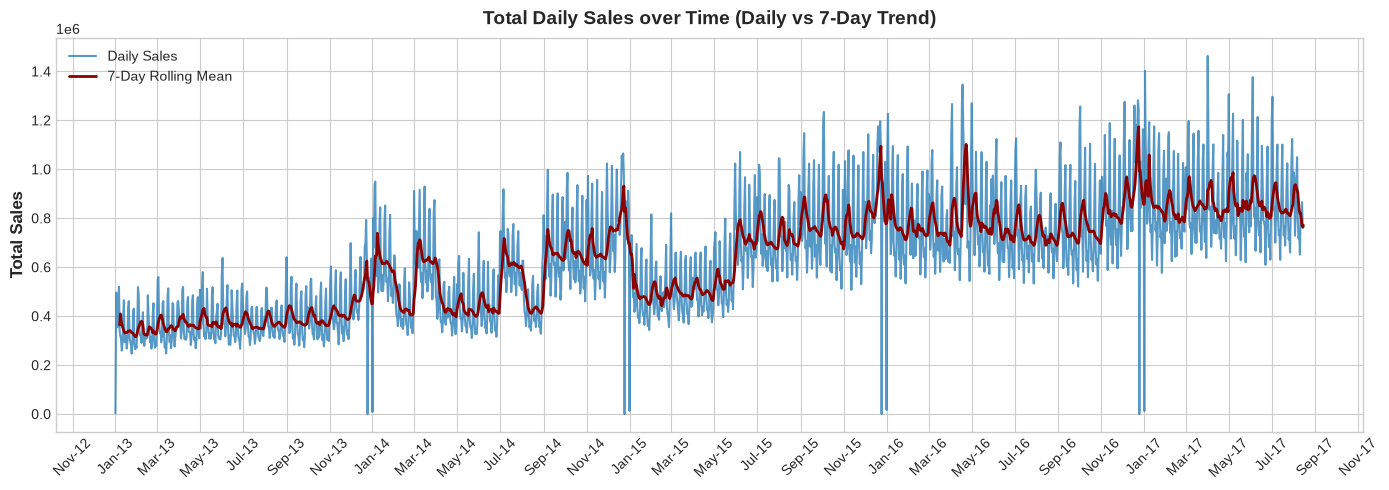

In [10]:
daily_sales = (
    df_train
    .groupby('date', as_index=False)['sales']
    .sum()
    .rename(columns={'sales': 'total_sales'})
)

# 7-day moving average
daily_sales['rolling_7d'] = daily_sales['total_sales'].rolling(7).mean()

# Daily sales
ax = sns.lineplot(
    data=daily_sales, 
    x='date', 
    y='total_sales',
    alpha=0.75,
    label='Daily Sales',
    )

# Superimposed 7-Day Rolling Mean
sns.lineplot(
    data=daily_sales,
    x='date',
    y='rolling_7d',
    ax=ax,
    color="darkred",
    linewidth=2,
    label="7-Day Rolling Mean",
)

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b-%y'))
plt.xticks(rotation=45, fontsize=10)
plt.ylabel('Total Sales')
plt.xlabel('')
plt.title('Total Daily Sales over Time (Daily vs 7-Day Trend)')
ax.legend(loc="upper left")
plt.show()

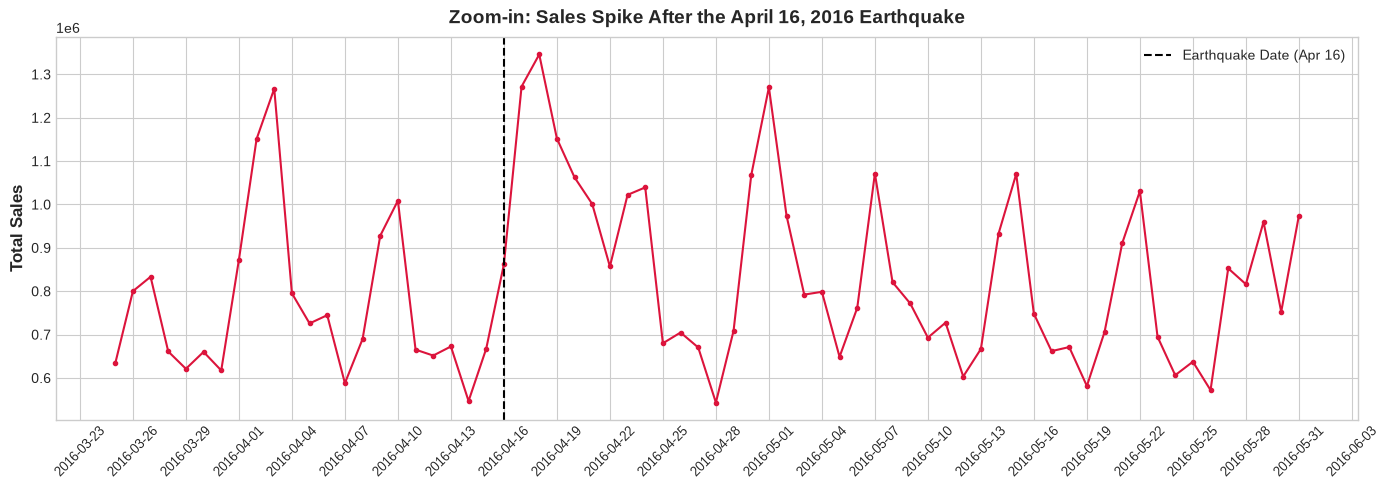

In [11]:
# Zoom-in around the earthquake period (March – April 2016)
earthquake_zoom = (
    daily_sales
    #~3 weeks prior and 6 weeks after the earthquake
    .query("date >= '2016-03-25' & date <= '2016-05-31'")
)

plt.plot(
    earthquake_zoom['date'],
    earthquake_zoom['total_sales'],
    marker='.',
    color='crimson',
)
plt.axvline(
    pd.to_datetime('2016-04-16'),
    color='black',
    linestyle='--',
    label='Earthquake Date (Apr 16)',
)

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
plt.xticks(rotation=45, fontsize=9)

plt.title('Zoom-in: Sales Spike After the April 16, 2016 Earthquake')
plt.ylabel('Total Sales')
plt.legend()
plt.show()

**Key Takeaways from Total Daily Sales:**
* **Long-Term Growth:** Sales show a clear upward trend from 2013 through mid-2017.

* **Recurring Seasonality:** Strong cyclical patterns remain visible even after 7-day smoothing, pointing to bi-weekly payday effects and end-of-year effects.

* **Christmas & New Year's Day Closures:** Sales drop to nearly zero on December 25 and January 1st every year when almost all stores are closed.

* **Earthquake Shock (April 2016):** A sharp, sustained sales spike occurs right after the April 16, 2016 earthquake in Ecuador due to emergency relief buying. Flagging this anomaly prevents tree models from distorting normal seasonal splits.

💡 **Features to build in Section 4:**
* `year`, `month`, `dayofyear`: Capture long-term growth and annual seasonality.

* `is_christmas` & `is_nyd`: Binary flags for Christmas and New Year's Day store closures.

* `is_earthquake_period`: Binary indicator derived directly from the `holiday_name` column (`Terremoto Manabi` and its 30-day post-event flags) to capture the massive demand shock and subsequent recovery in the affected region following the April 16, 2016 earthquake.

### 3.2 Product Family & Store Scale
Compare average daily sales across the top product families and top-performing stores to understand major scale differences.

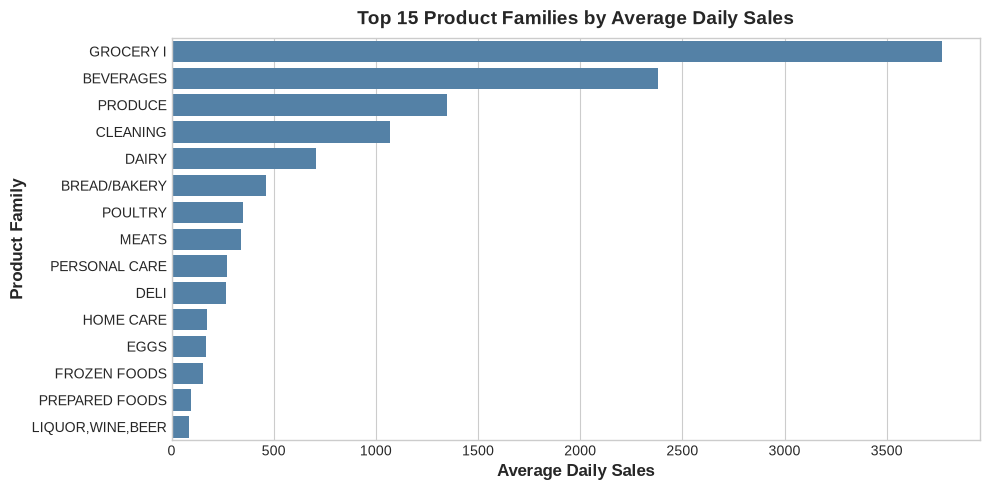

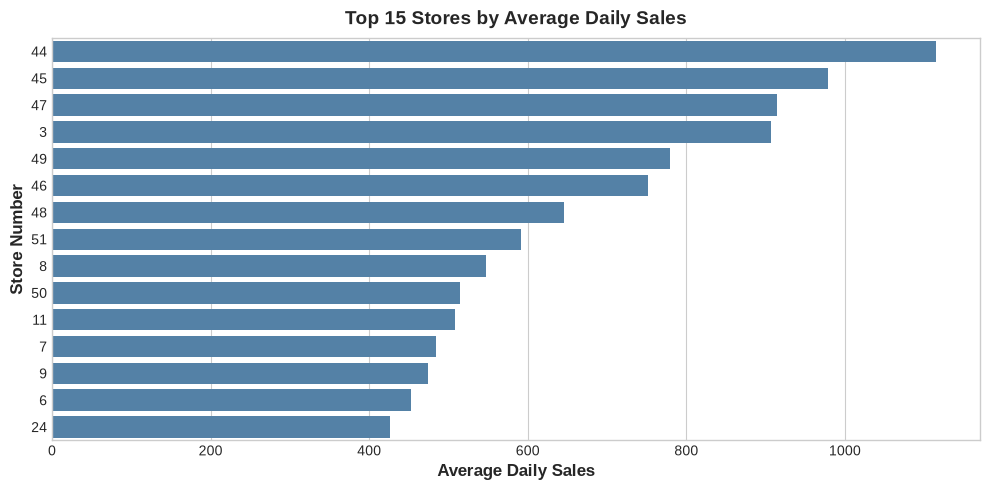

In [12]:
# Top 15 Product Families by Average Sales
top_families = (
    df_train.groupby('family', as_index=False)['sales']
    .mean()
    .sort_values(by='sales', ascending=False)
    .head(15)
)

plt.figure(figsize=(10, 5))
sns.barplot(data=top_families, x='sales', y='family', color='steelblue')
plt.title('Top 15 Product Families by Average Daily Sales')
plt.xlabel('Average Daily Sales')
plt.ylabel('Product Family')
plt.show()

# Top 15 Stores by Average Sales
top_stores = (
    df_train.groupby('store_nbr', as_index=False)['sales']
    .mean()
    .sort_values(by='sales', ascending=False)
    .head(15)
)

top_stores['store_nbr'] = top_stores['store_nbr'].astype(str)

plt.figure(figsize=(10, 5))
sns.barplot(data=top_stores, x='sales', y='store_nbr', color='steelblue')
plt.title('Top 15 Stores by Average Daily Sales')
plt.xlabel('Average Daily Sales')
plt.ylabel('Store Number')
plt.show()

**Key Takeaways on Families and Stores:**
* **Store Types & Family Categories:** Sales volume varies massively across product families (e.g., `GROCERY I` leading) and stores, justifying the inclusion of categorical identifiers (`family`, `store_nbr`, `store_type`, `cluster`).

* **Geographic Hierarchy (`city`, `state`):** Will retain alongside `store_nbr`, `store_type`, and `cluster` to allow tree models to group stores regionally with a single split. Particularly useful for isolating regional anomalies like the Manabi earthquake shock or local city-level demand patterns.

💡 **Features to build in Section 4:**
* `store_nbr`, `family`, `city`, `state`, `store_type`, `cluster` (plus `holiday_name`): Cast to `category` dtype on the combined dataset so tree-based models can perform optimal categorical splits.

### 3.3 Average Sales per Day of Month (Payday Effect)
In Ecuador, public sector wages are paid bi-weekly on the 15th and on the last day of the month. Here, we check how this payment schedule affects daily shopping behavior.

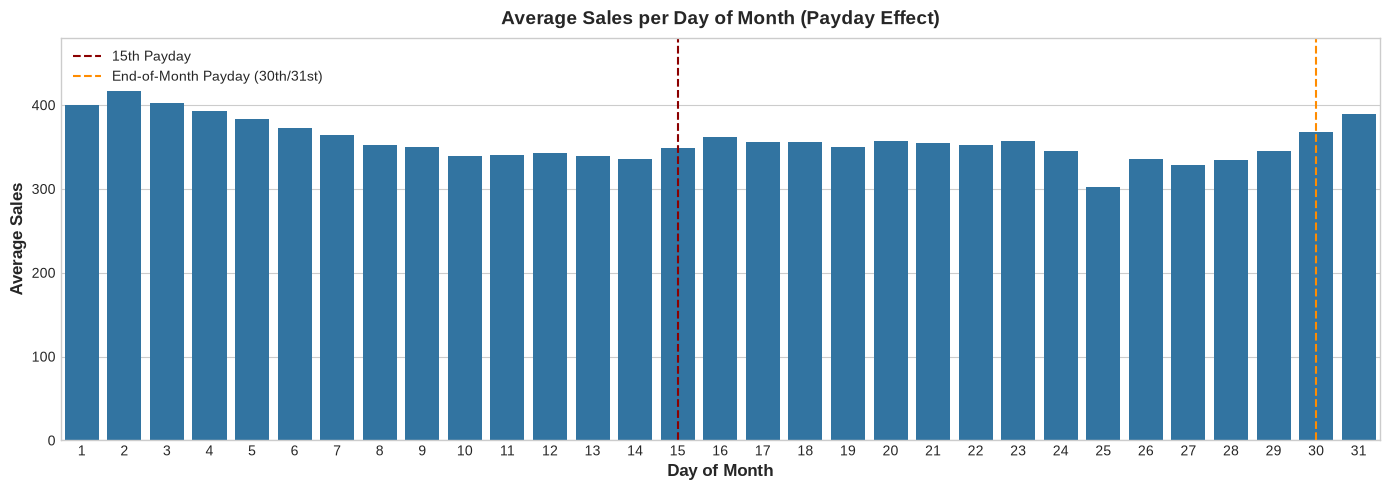

In [13]:
sales_per_dayofmonth = (
    df_train
    .assign(
        dayofmonth = lambda df: df['date'].dt.day
    )
    .groupby('dayofmonth', as_index=False)['sales']
    .mean()
    .rename(columns={'dayofmonth': 'day', 'sales': 'avg_sales'})
)

# Daily sales
ax = sns.barplot(
    data=sales_per_dayofmonth, 
    x='day', 
    y='avg_sales',
    )

plt.axvline(x=14, color='darkred', linestyle='--', linewidth=1.5, label='15th Payday')
plt.axvline(x=29, color='darkorange', linestyle='--', linewidth=1.5, label='End-of-Month Payday (30th/31st)')

plt.ylabel('Average Sales')
plt.xlabel('Day of Month')
plt.title('Average Sales per Day of Month (Payday Effect)')
plt.legend(loc='upper left')
plt.ylim(0, 480)
plt.show()

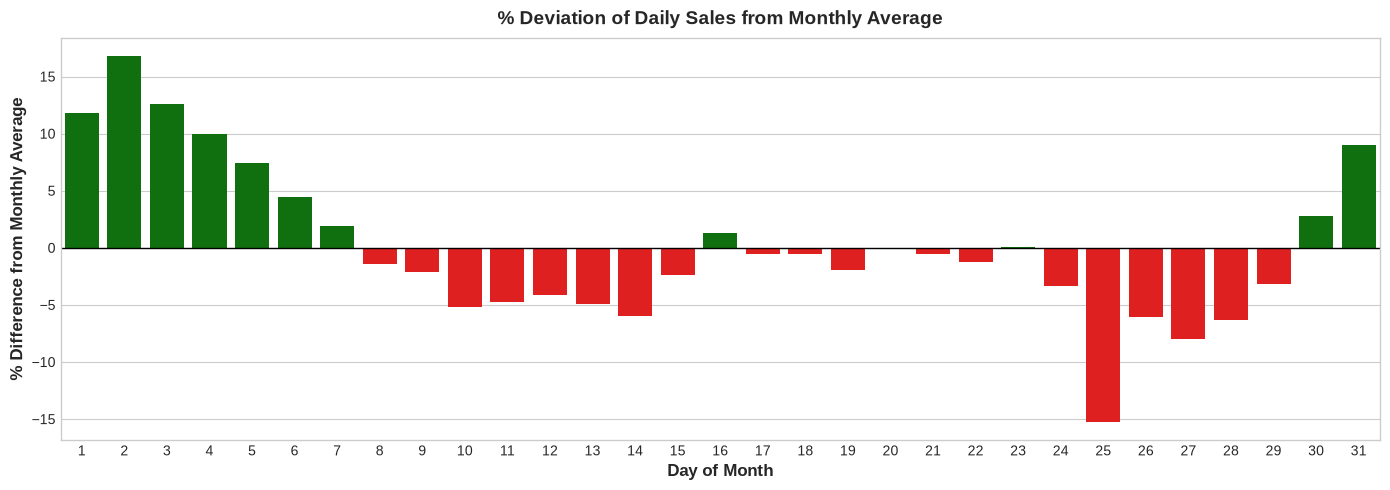

In [14]:
mean_sales = sales_per_dayofmonth['avg_sales'].mean()
sales_per_dayofmonth['pct_diff'] = ((sales_per_dayofmonth['avg_sales'] - mean_sales) / mean_sales) * 100

colors = ['green' if x > 0 else 'red' for x in sales_per_dayofmonth['pct_diff']]

ax = sns.barplot(
    data=sales_per_dayofmonth, 
    x='day', 
    y='pct_diff', 
    hue='day',
    palette=colors,
    legend=False
)

plt.axhline(0, color='black', linewidth=1)
plt.ylabel('% Difference from Monthly Average')
plt.xlabel('Day of Month')
plt.title('% Deviation of Daily Sales from Monthly Average')
plt.show()

**Key Takeaways from Monthly Sales Patterns (Payday Effect):**
* **Start-of-Month Surge (Days 1–4):** Sales are consistently highest during the first four days of the month (+10% to +17% above the monthly average), peaking on day 2 right after end-of-month paychecks are issued.

* **Mid-Month Bump (Days 15–16):** Sales dip to a local low on day 14 (-6%), then rebound on the 15th and turn positive on the 16th following the mid-month payday.

* **End-of-Month Uptick & Christmas Dip:** Sales rise again on days 30–31 (+3% to +9%), while the sharp dip on day 25 (-15%) is skewed by Christmas Day store closures.

💡 **Features to build in Section 4:**
* `dayofmonth`: Day of the month (1–31) to let tree models learn the daily trend.

* `is_month_start_end`: Binary indicator for days [1, 2, 3, 4, `is_month_end`] to capture the primary end-of-month paycheck wave (+10% to +17%).

* `is_mid_payday`: Binary indicator for days [15, 16] to isolate the secondary mid-month salary bump.

### 3.4 Average Sales per Weekday (Weekend Effect)
Examine how customer demand shifts across the days of the week (`Monday = 0` to `Sunday = 6`).

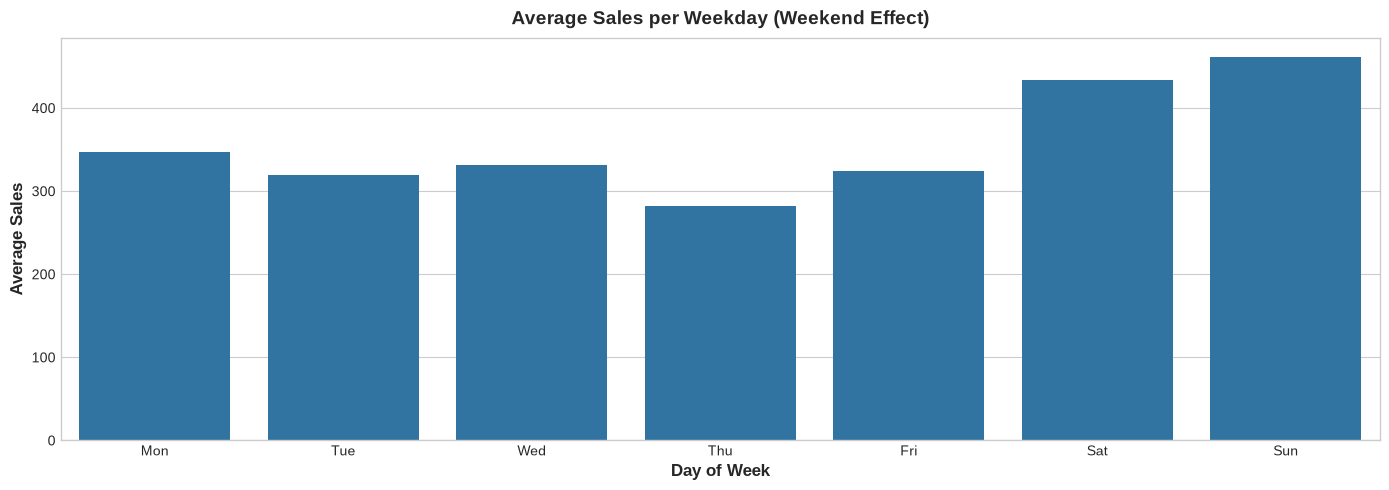

In [15]:
day_mapping = {
    0: 'Mon',
    1: 'Tue',
    2: 'Wed',
    3: 'Thu',
    4: 'Fri',
    5: 'Sat',
    6: 'Sun',
}

sales_per_weekday = (
    df_train
    .assign(weekday = lambda df: df['date'].dt.dayofweek)
    .groupby('weekday', as_index=False)['sales']
    .mean()
    .rename(columns={'sales': 'avg_sales'})
    .assign(weekday_name=lambda df: df['weekday'].map(day_mapping))
)

# Daily sales
ax = sns.barplot(
    data=sales_per_weekday, 
    x='weekday_name', 
    y='avg_sales',
    )

plt.ylabel('Average Sales')
plt.xlabel('Day of Week')
plt.title('Average Sales per Weekday (Weekend Effect)')
plt.show()

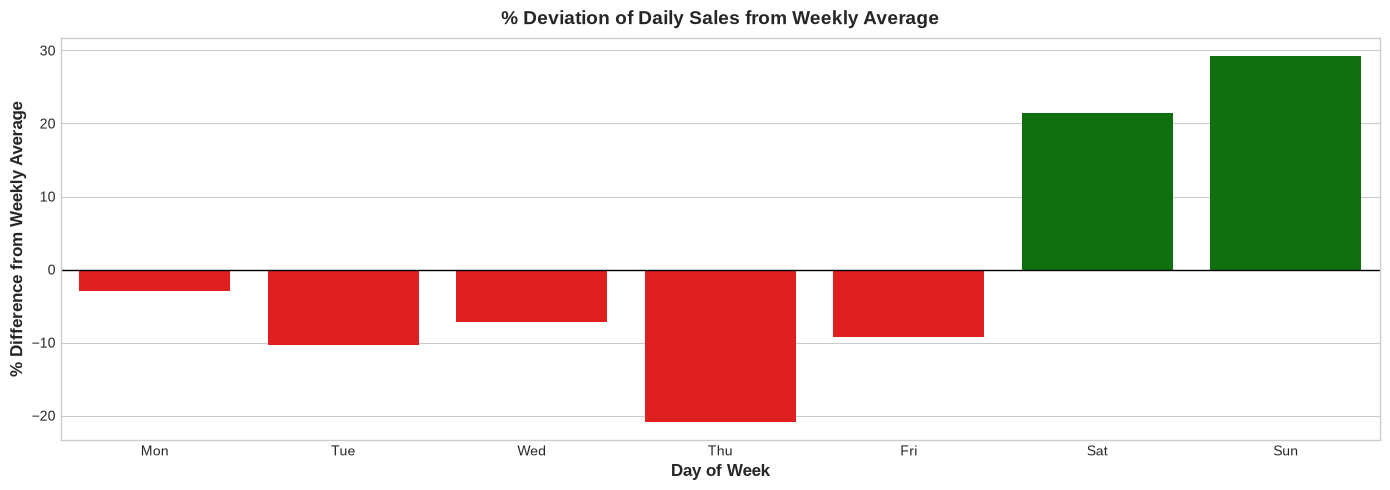

In [16]:
mean_sales = sales_per_weekday['avg_sales'].mean()
sales_per_weekday['pct_diff'] = ((sales_per_weekday['avg_sales'] - mean_sales) / mean_sales) * 100

colors = ['green' if x > 0 else 'red' for x in sales_per_weekday['pct_diff']]

ax = sns.barplot(
    data=sales_per_weekday, 
    x='weekday_name', 
    y='pct_diff', 
    hue='weekday_name',
    palette=colors,
    legend=False
)

plt.axhline(0, color='black', linewidth=1)
plt.ylabel('% Difference from Weekly Average')
plt.xlabel('Day of Week')
plt.title('% Deviation of Daily Sales from Weekly Average')
plt.show()

**Key Takeaways from Weekly Sales Patterns (Weekend Effect):**
* **Weekday (Monday–Friday):** Sales remain below the weekly average throughout the entire workweek. Monday is the strongest weekday, while Thursday is the slowest day of the week.

* **Weekend (Saturday–Sunday):** Retail traffic jumps sharply over the weekend, with sales rising **+21% on Saturday** and peaking at nearly **+30% above average on Sunday**.

💡 **Features to build in Section 4:**
* `dayofweek` (0–6): Standard day-of-week integer so tree-based models can learn the distinct pattern of each individual day (especially capturing the heavy weekend spike).

### 3.5 Oil Price & Macroeconomic Momentum vs. Sales
Ecuador's economy relies heavily on oil exports. Raw daily spot prices contain high-frequency market noise and undergo severe multi-year regime shifts (dropping from ~$100 to ~$40 between 2014 and 2015). Here, we engineer smoothed 28-day rolling averages, 28-day rolling volatility (`std`), relative deviation from the 28-day moving average, and Month-over-Month (MoM) percentage changes (`28-day` point-in-time and trend momentum) to evaluate both macroeconomic trends and scale-free shocks against retail sales.

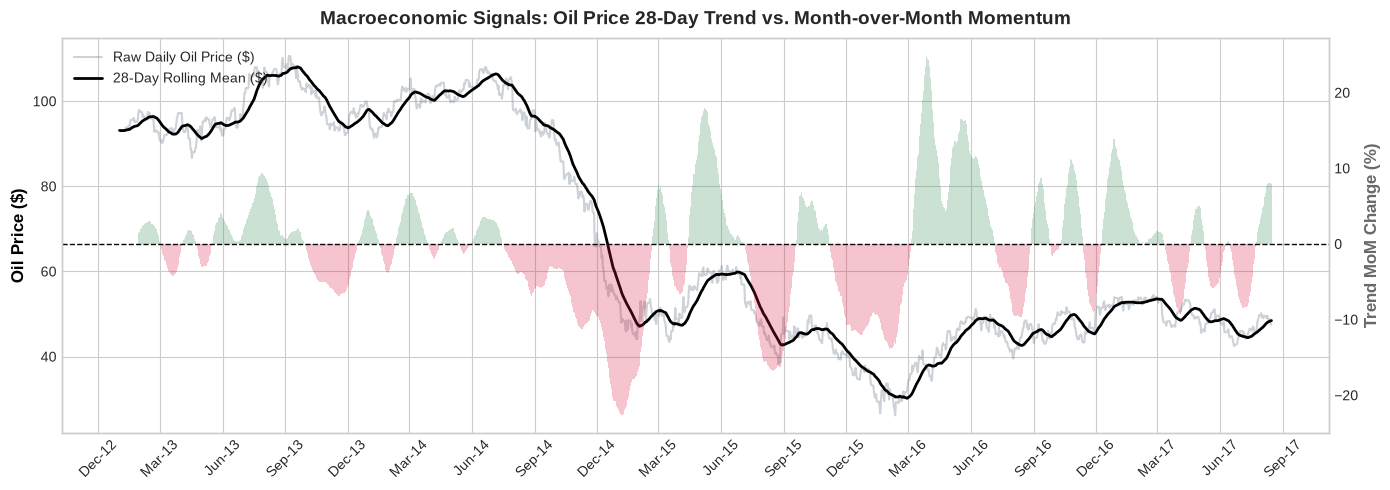

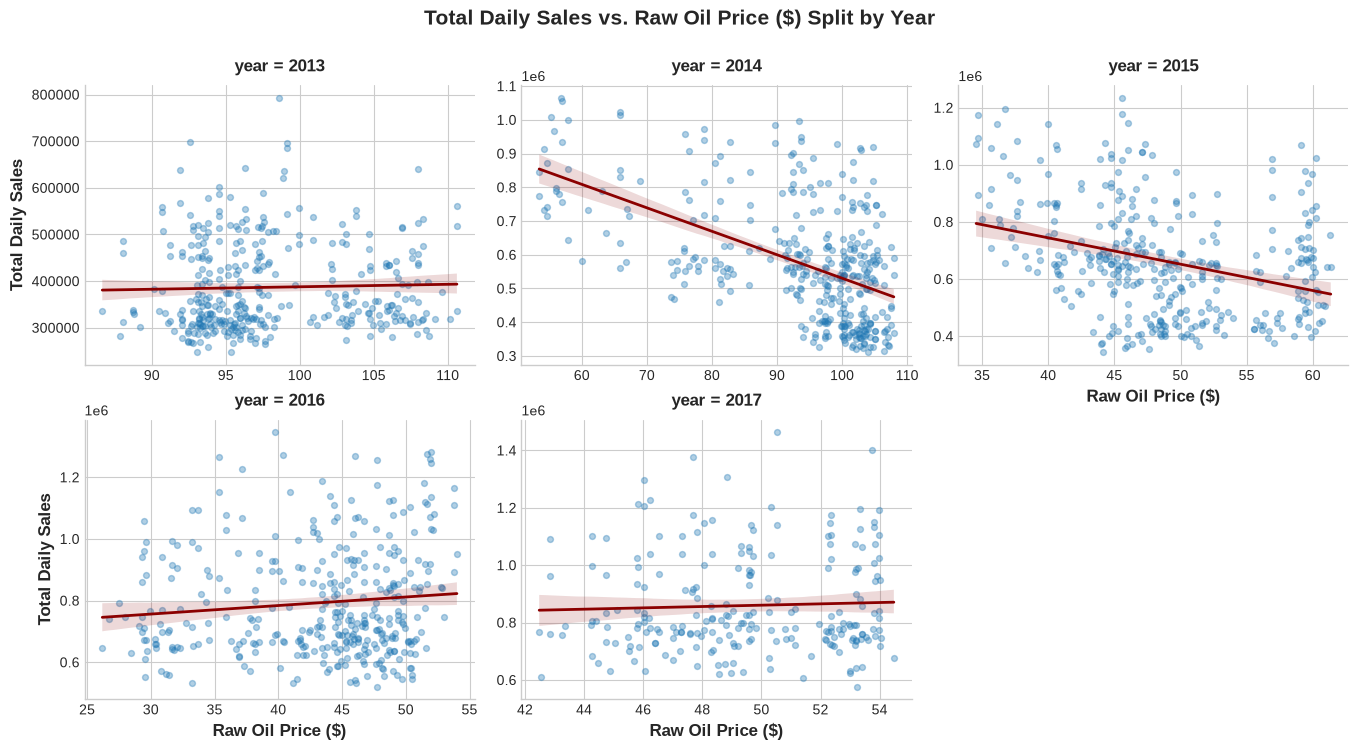

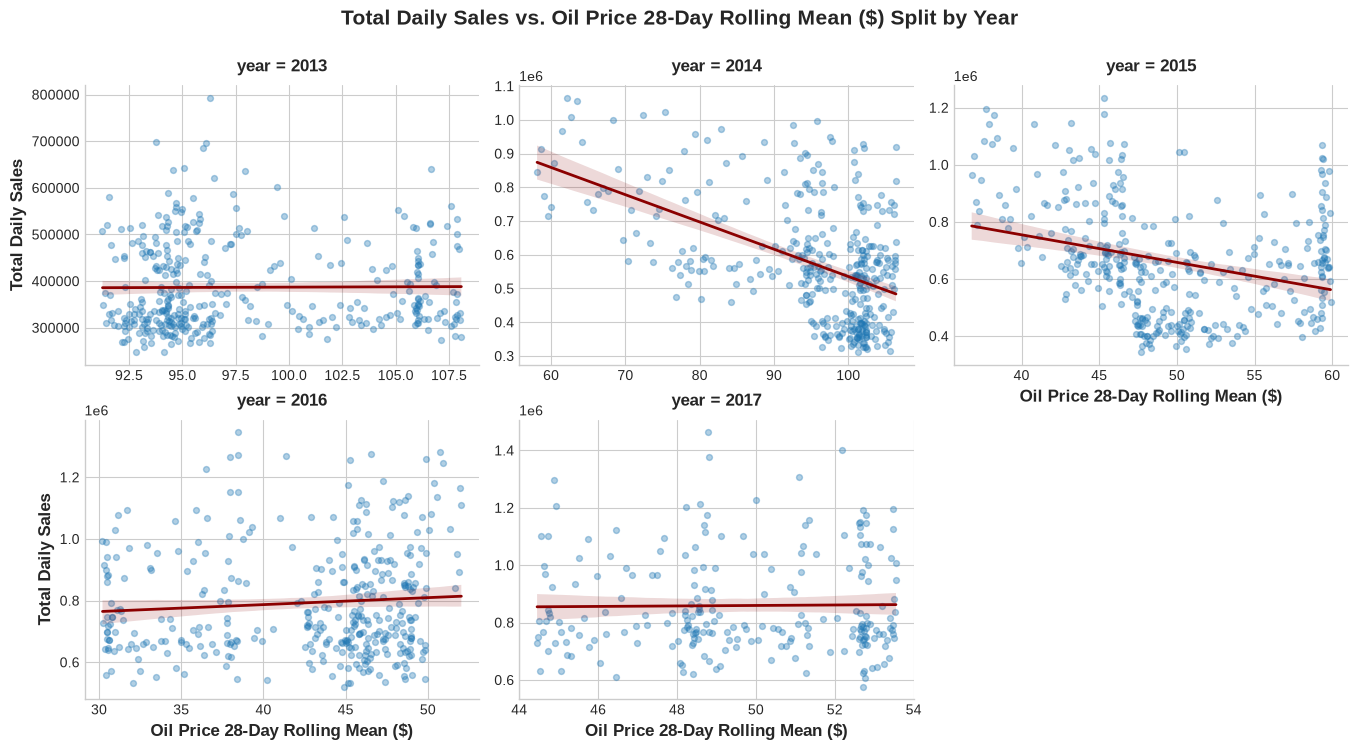

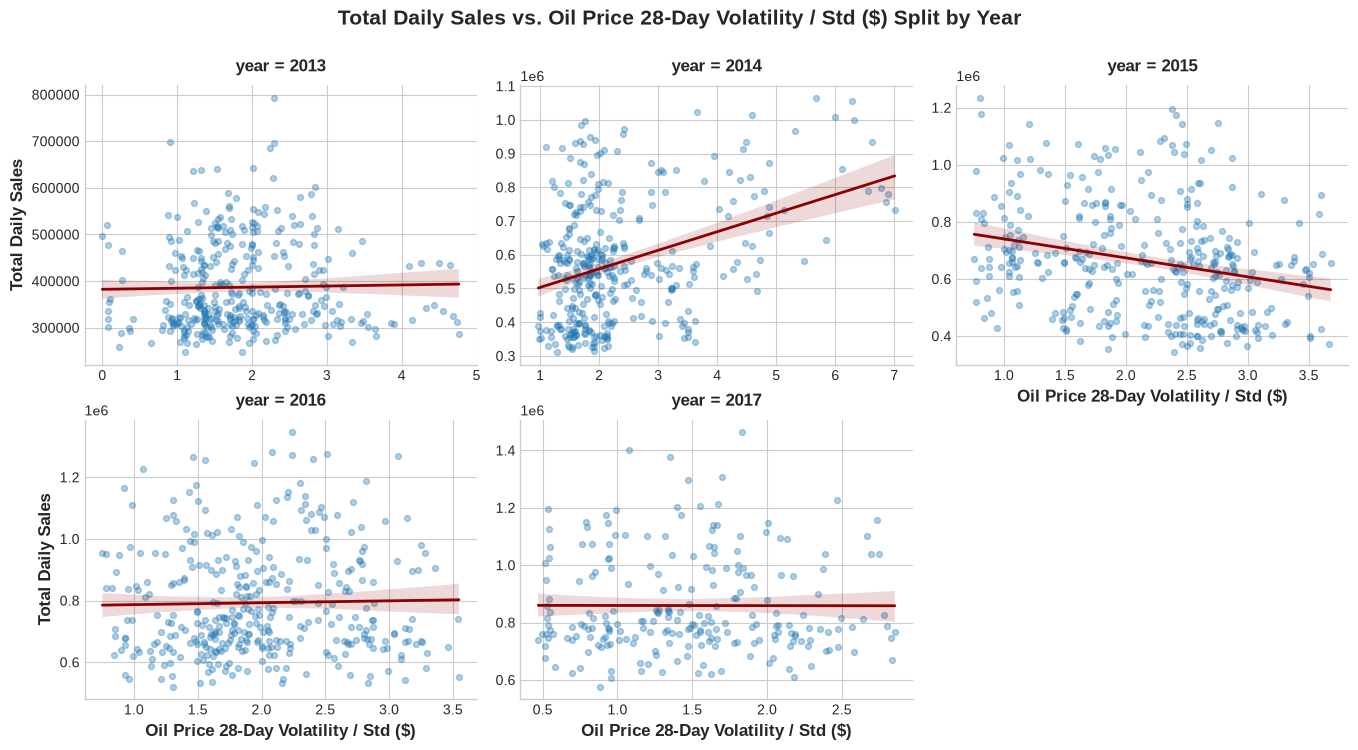

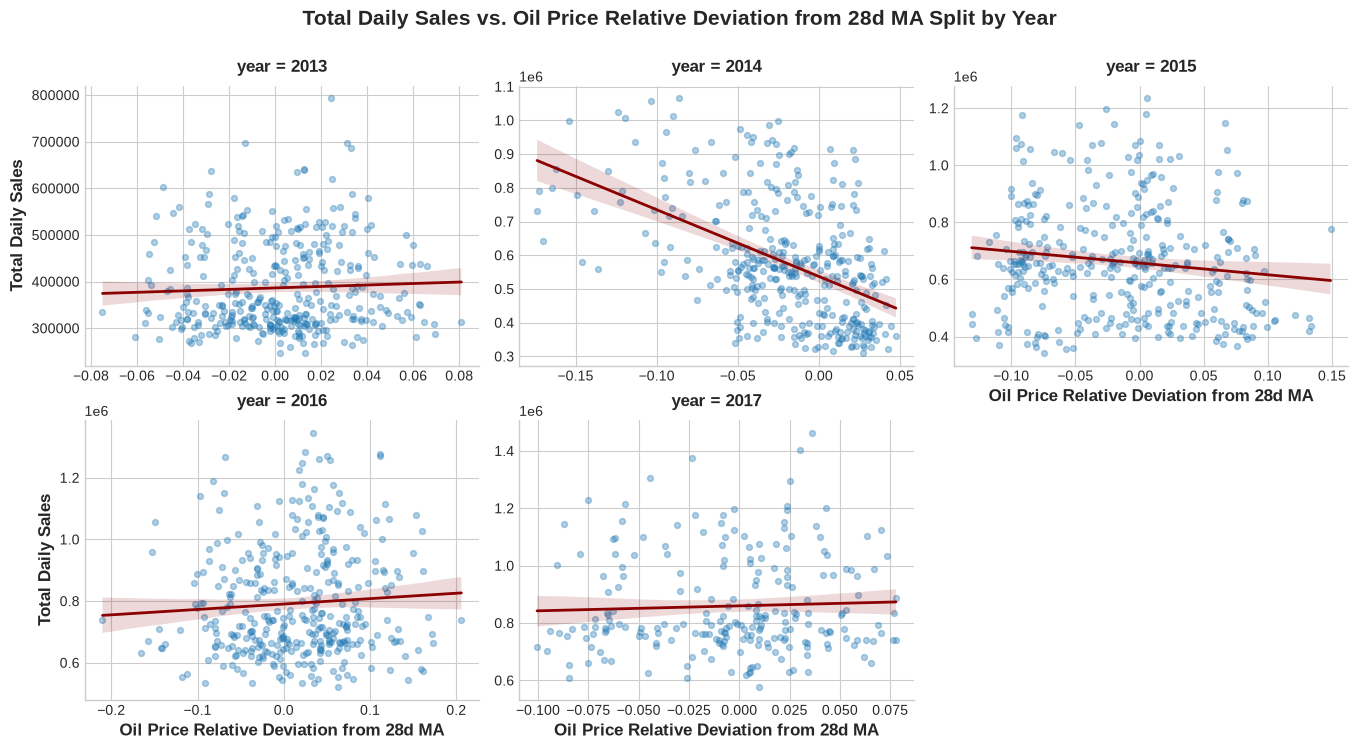

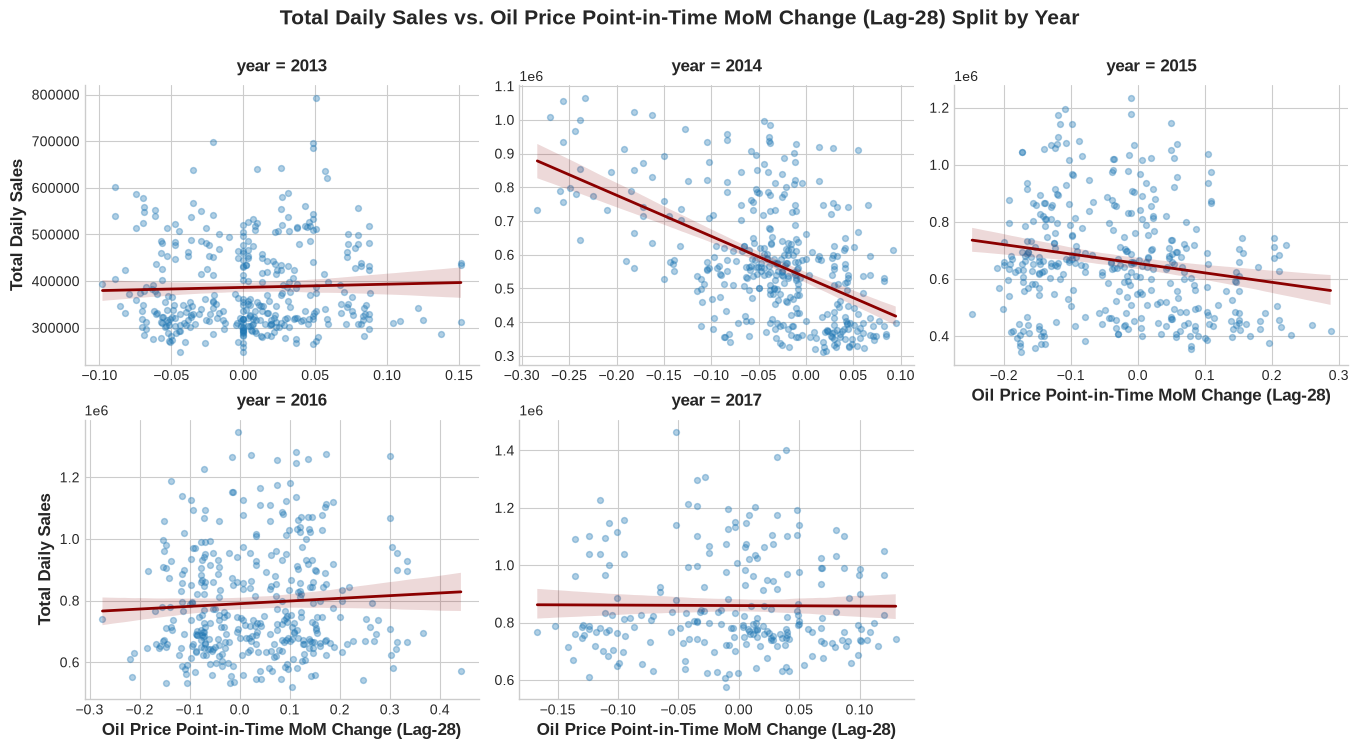

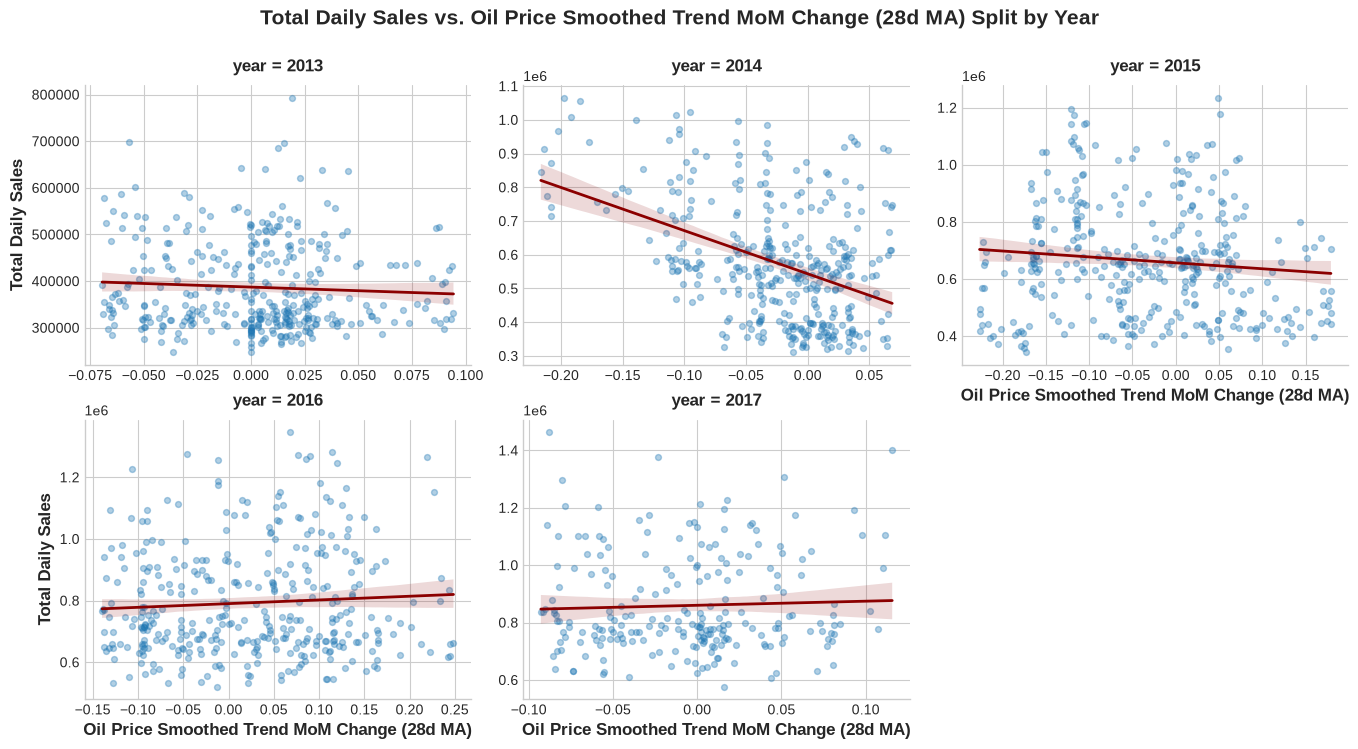

In [17]:
# 1. Compute daily macroeconomic oil features on the unique date timeline
daily_oil = (
    df_train[['date', 'oil_price']]
    .drop_duplicates(subset='date')
    .sort_values('date')
    .reset_index(drop=True)
    .assign(
        oil_price_rolling_mean_28=lambda x: x['oil_price'].rolling(window=28, min_periods=1).mean(),
        oil_price_rolling_std_28=lambda x: x['oil_price'].rolling(window=28, min_periods=1).std().fillna(0.0),
        oil_price_lag28=lambda x: x['oil_price'].shift(28),
        oil_price_lag28_rolling_mean_28=lambda x: x['oil_price_rolling_mean_28'].shift(28),
        oil_price_dev_ma28_pct=lambda x: (
            (x['oil_price'] - x['oil_price_rolling_mean_28'])
            / x['oil_price_rolling_mean_28'].replace(0, np.nan)
        ).fillna(0.0),
        oil_price_point_mom_pct=lambda x: (
            (x['oil_price'] - x['oil_price_lag28'])
            / x['oil_price_lag28'].replace(0, np.nan)
        ).fillna(0.0),
        oil_price_trend_mom_pct=lambda x: (
            (x['oil_price_rolling_mean_28'] - x['oil_price_lag28_rolling_mean_28'])
            / x['oil_price_lag28_rolling_mean_28'].replace(0, np.nan)
        ).fillna(0.0),
    )
    .drop(columns=['oil_price_lag28', 'oil_price_lag28_rolling_mean_28'])
)

oil_vs_sales = (
    pd.merge(daily_sales, daily_oil, on='date', how='inner')
    .query('total_sales > 100000')  # Exclude Christmas and New Year's Day closures
    .assign(year=lambda df: df['date'].dt.year)
)

# 2. Plot Oil Price Trend (28d MA) vs. Month-over-Month Momentum
fig, ax1 = plt.subplots(figsize=(14, 5))

ax1.plot(
    daily_oil['date'],
    daily_oil['oil_price'],
    alpha=0.35,
    color='slategray',
    label='Raw Daily Oil Price ($)',
)
ax1.plot(
    daily_oil['date'],
    daily_oil['oil_price_rolling_mean_28'],
    color='black',
    linewidth=2,
    label='28-Day Rolling Mean ($)',
)
ax1.set_ylabel('Oil Price ($)', color='black', fontweight='bold')
ax1.legend(loc='upper left')

ax2 = ax1.twinx()
mom_colors = np.where(daily_oil['oil_price_trend_mom_pct'] >= 0, 'seagreen', 'crimson')
ax2.bar(
    daily_oil['date'],
    daily_oil['oil_price_trend_mom_pct'] * 100.0,
    color=mom_colors,
    alpha=0.25,
    width=1.0,
    label='28d Trend MoM % Change',
)
ax2.axhline(0, color='black', linewidth=1, linestyle='--')
ax2.set_ylabel('Trend MoM Change (%)', color='dimgray', fontweight='bold')
ax2.grid(False)

ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b-%y'))
plt.setp(ax1.get_xticklabels(), rotation=45, fontsize=10)
plt.title('Macroeconomic Signals: Oil Price 28-Day Trend vs. Month-over-Month Momentum')
plt.show()

# 3. Year-by-Year OLS Regressions across all Oil Features
oil_features_config = [
    ('oil_price', 'Raw Oil Price ($)'),
    ('oil_price_rolling_mean_28', 'Oil Price 28-Day Rolling Mean ($)'),
    ('oil_price_rolling_std_28', 'Oil Price 28-Day Volatility / Std ($)'),
    ('oil_price_dev_ma28_pct', 'Oil Price Relative Deviation from 28d MA'),
    ('oil_price_point_mom_pct', 'Oil Price Point-in-Time MoM Change (Lag-28)'),
    ('oil_price_trend_mom_pct', 'Oil Price Smoothed Trend MoM Change (28d MA)'),
]

for col, label in oil_features_config:
    g = sns.lmplot(
        data=oil_vs_sales,
        x=col,
        y='total_sales',
        col='year',
        col_wrap=3,
        height=3.8,
        aspect=1.2,
        scatter_kws={'alpha': 0.35, 's': 18},
        line_kws={'color': 'darkred', 'linewidth': 2},
        facet_kws={'sharex': False, 'sharey': False},
    )
    g.set_axis_labels(label, 'Total Daily Sales')
    g.figure.subplots_adjust(top=0.88)
    g.figure.suptitle(
        f'Total Daily Sales vs. {label} Split by Year',
        fontsize=15,
        fontweight='bold',
    )
    plt.show()

**Key Takeaways on Oil Prices & Macroeconomic Momentum:**

> **v1.1.0 Experiment Note:** In the `v1.0.0` pipeline, raw daily oil prices were excluded because they added noise and degraded validation performance. For `v1.1.0`, we hypothesized that extracting smoothed, stationary macro signals (28-day rolling means, volatility, and Month-over-Month momentum) might capture purchasing power changes without the daily noise.

* **Zero Short-Term Predictive Signal:** Looking at the years 2013, 2016, and 2017 across all engineered features (rolling means, volatility, and MoM percentages), the regression lines are completely flat. Fluctuations in oil prices do not directly drive everyday grocery shopping behavior in the short term.

* **Identifying Spurious Correlation (2014):** The strong negative slope observed in 2014 is a classic spurious correlation. Global crude prices crashed dramatically between September and December 2014. This macro event perfectly overlapped with the standard November-December holiday shopping surge (Christmas), creating a false mathematical link between dropping oil prices and rising grocery sales.

* **Conclusion (Final Feature Inclusion):** Re-evaluating our `v1.0.0` intuition, while the raw daily oil price introduced noise, the 65-feature baseline revealed that the macroeconomic signal is critical for anchoring the global trend once micro-volatility is captured. Therefore, we will include all engineered oil-related features (rolling means, volatility, and MoM percentages) in the final Feature Engineering pipeline (Section 4) to allow the gradient boosting models to natively select the optimal macro predictors. We will further test if these features need to be discarded when evaluating the XGBoost and LightGBM models.

### 3.6 Promotions vs. Sales
Examine the distribution of `onpromotion` (number of items on promotion within a store-family) and its impact on sales.

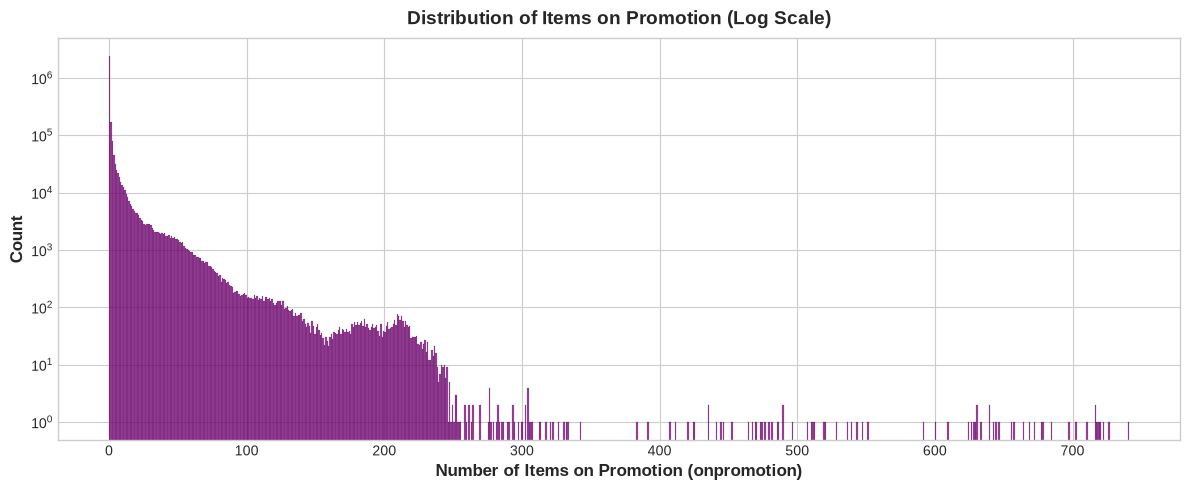

In [18]:
plt.figure(figsize=(12, 5))
sns.histplot(
    data=df_train,
    x='onpromotion',
    binwidth=1,
    color='purple',
)
plt.yscale('log')
plt.title('Distribution of Items on Promotion (Log Scale)')
plt.xlabel('Number of Items on Promotion (onpromotion)')
plt.ylabel('Count')
plt.show()


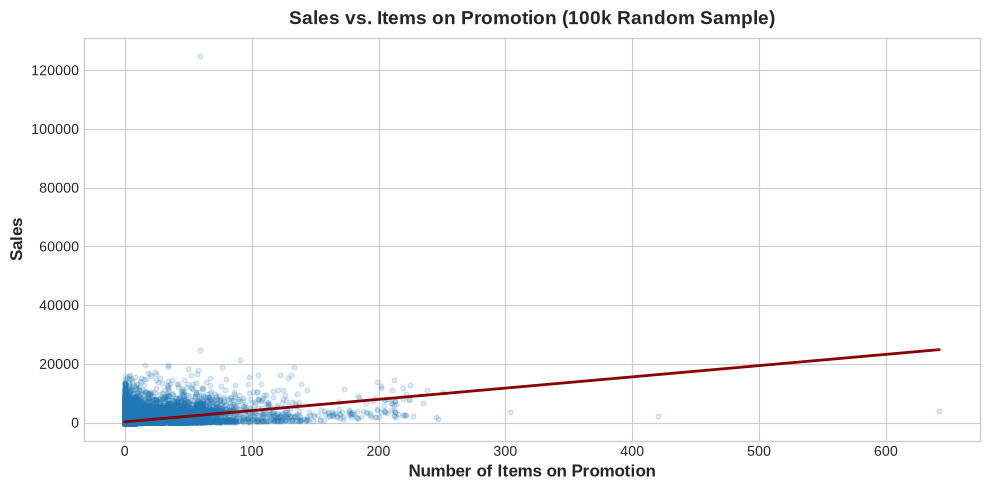

In [19]:
df_sample = df_train.sample(n=100000, random_state=0)

plt.figure(figsize=(10, 5))
sns.regplot(
    data=df_sample,
    x='onpromotion',
    y='sales',
    ci=None,
    scatter_kws={'alpha': 0.15, 's': 12},
    line_kws={'color': 'darkred', 'linewidth': 2},
)
plt.title('Sales vs. Items on Promotion (100k Random Sample)')
plt.xlabel('Number of Items on Promotion')
plt.ylabel('Sales')
plt.show()

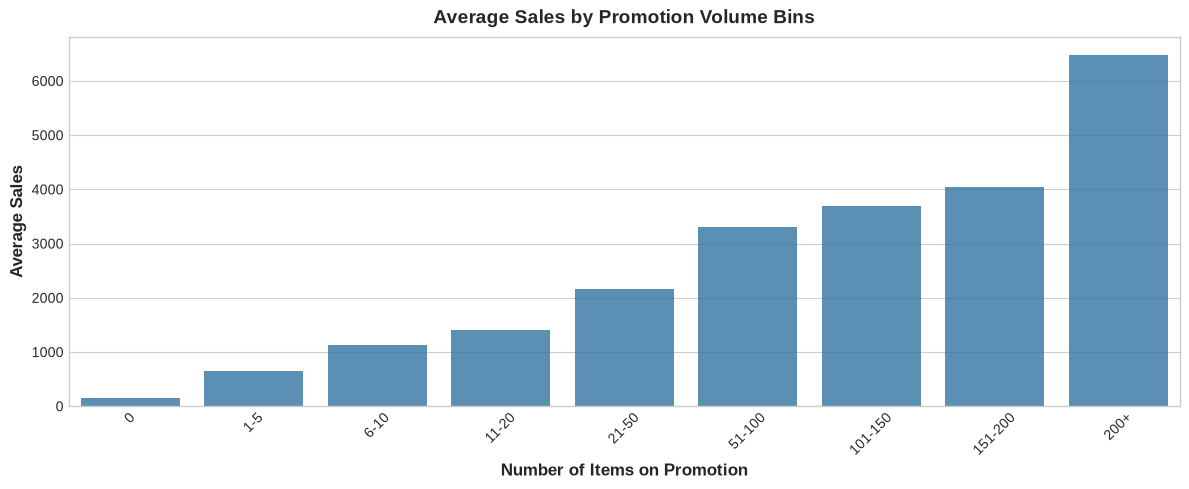

In [20]:
bins = [-1, 0, 5, 10, 20, 50, 100, 150, 200, 1000]
labels = [
    '0',
    '1-5',
    '6-10',
    '11-20',
    '21-50',
    '51-100',
    '101-150',
    '151-200',
    '200+',
]

promo_binned = (
    df_train.assign(
        promo_bin=pd.cut(
            df_train['onpromotion'], bins=bins, labels=labels
        )
    )
    .groupby('promo_bin', as_index=False, observed=False)['sales']
    .mean()
    .rename(columns={'sales': 'avg_sales'})
)

plt.figure(figsize=(12, 5))
sns.barplot(
    data=promo_binned, 
    x='promo_bin', 
    y='avg_sales', 
    alpha=0.8
)
plt.title('Average Sales by Promotion Volume Bins',)
plt.xlabel('Number of Items on Promotion')
plt.ylabel('Average Sales')
plt.xticks(rotation=45)
plt.show()

In [21]:
temp_df = df_train[['date', 'store_nbr', 'family', 'sales', 'onpromotion']].copy()

temp_df['promo_lag_1'] = temp_df.groupby(['store_nbr', 'family'])['onpromotion'].shift(1)
temp_df['promo_lead_1'] = temp_df.groupby(['store_nbr', 'family'])['onpromotion'].shift(-1)

print('Correlation with sales:')
print(f"Same day (onpromotion): {temp_df['sales'].corr(temp_df['onpromotion']):.3f}")
print(f"Previous day (lag_1):   {temp_df['sales'].corr(temp_df['promo_lag_1']):.3f}")
print(f"Next day (lead_1):      {temp_df['sales'].corr(temp_df['promo_lead_1']):.3f}")

Correlation with sales:
Same day (onpromotion): 0.428
Previous day (lag_1):   0.373
Next day (lead_1):      0.376


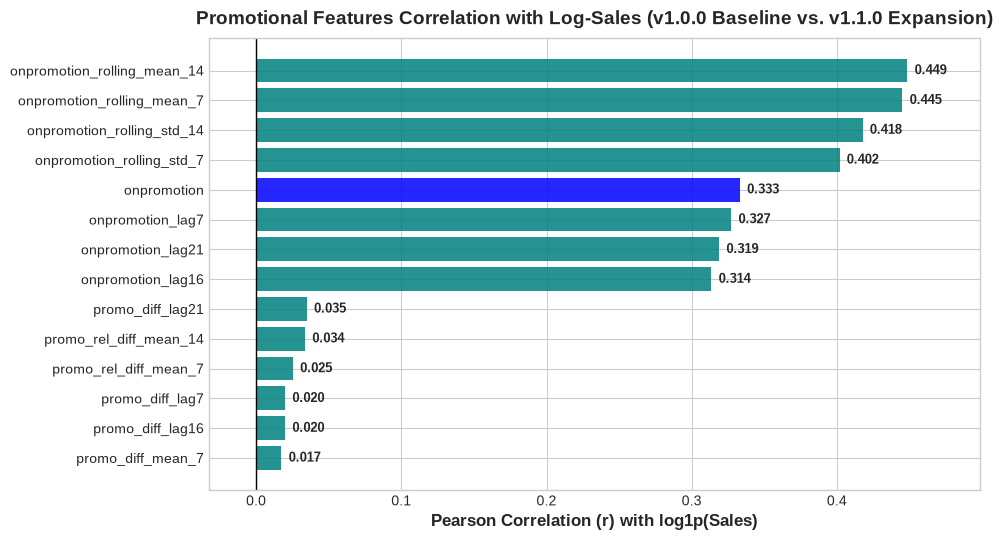

57

In [22]:
# v1.1.0 EDA: Promotional Context, Rolling Intensity & Momentum Features
promo_eda_df = (
    df_train[['date', 'store_nbr', 'family', 'sales', 'onpromotion']]
    .sort_values(['store_nbr', 'family', 'date'])
    .reset_index(drop=True)
)

promo_grp = promo_eda_df.groupby(['store_nbr', 'family'], sort=False)['onpromotion']

promo_eda_df['onpromotion_lag7'] = promo_grp.shift(7)
promo_eda_df['onpromotion_lag16'] = promo_grp.shift(16)
promo_eda_df['onpromotion_lag21'] = promo_grp.shift(21)
promo_eda_df['onpromotion_rolling_mean_7'] = promo_grp.transform(lambda s: s.rolling(7, min_periods=1).mean())
promo_eda_df['onpromotion_rolling_std_7'] = promo_grp.transform(lambda s: s.rolling(7, min_periods=1).std()).fillna(0.0)
promo_eda_df['onpromotion_rolling_mean_14'] = promo_grp.transform(lambda s: s.rolling(14, min_periods=1).mean())
promo_eda_df['onpromotion_rolling_std_14'] = promo_grp.transform(lambda s: s.rolling(14, min_periods=1).std()).fillna(0.0)

# Signed promotion deltas and Laplace-smoothed relative changes
promo_eda_df['promo_diff_lag7'] = promo_eda_df['onpromotion'] - promo_eda_df['onpromotion_lag7']
promo_eda_df['promo_diff_lag16'] = promo_eda_df['onpromotion'] - promo_eda_df['onpromotion_lag16']
promo_eda_df['promo_diff_lag21'] = promo_eda_df['onpromotion'] - promo_eda_df['onpromotion_lag21']
promo_eda_df['promo_diff_mean_7'] = promo_eda_df['onpromotion'] - promo_eda_df['onpromotion_rolling_mean_7']
promo_eda_df['promo_rel_diff_mean_7'] = (
    (promo_eda_df['onpromotion'] - promo_eda_df['onpromotion_rolling_mean_7'])
    / (promo_eda_df['onpromotion_rolling_mean_7'] + 1.0)
)
promo_eda_df['promo_rel_diff_mean_14'] = (
    (promo_eda_df['onpromotion'] - promo_eda_df['onpromotion_rolling_mean_14'])
    / (promo_eda_df['onpromotion_rolling_mean_14'] + 1.0)
)

promo_eda_df = promo_eda_df.query('date >= "2013-03-01"')
promo_eda_df['sales_log1p'] = np.log1p(promo_eda_df['sales'])

promo_cols = [
    'onpromotion',
    'onpromotion_rolling_mean_7',
    'onpromotion_rolling_mean_14',
    'onpromotion_lag7',
    'onpromotion_lag16',
    'onpromotion_lag21',
    'onpromotion_rolling_std_7',
    'onpromotion_rolling_std_14',
    'promo_rel_diff_mean_14',
    'promo_rel_diff_mean_7',
    'promo_diff_lag21',
    'promo_diff_lag16',
    'promo_diff_lag7',
    'promo_diff_mean_7',
]

promo_corrs = (
    promo_eda_df[promo_cols]
    .apply(lambda s: promo_eda_df['sales_log1p'].corr(s))
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 5.5))
bars = plt.barh(
    promo_corrs.index,
    promo_corrs.values,
    color=['blue' if c == 'onpromotion' else 'teal' for c in promo_corrs.index],
    alpha=0.85,
)
plt.axvline(0, color='black', linewidth=1)
plt.xlabel('Pearson Correlation (r) with log1p(Sales)')
plt.title('Promotional Features Correlation with Log-Sales (v1.0.0 Baseline vs. v1.1.0 Expansion)')
for bar in bars:
    val = bar.get_width()
    plt.text(
        val + (0.005 if val >= 0 else -0.028),
        bar.get_y() + bar.get_height() / 2,
        f'{val:.3f}',
        va='center',
        fontsize=9,
        fontweight='bold',
    )
plt.xlim(min(promo_corrs.values) - 0.05, max(promo_corrs.values) + 0.05)
plt.tight_layout()
plt.show()

del promo_eda_df, promo_grp
gc.collect()

**Key Takeaways on Promotions (`onpromotion`):**
* **Strong Positive Impact:** While raw promotion counts are heavily zero-inflated, grouping `onpromotion` into volume bins reveals a clear, step-by-step increase in average sales as active promotions rise.

* **High Forward-Looking Value:** Since `onpromotion` schedules are known in advance for the entire 16-day test horizon, all promotion lags, rolling averages, and deltas are 100% leak-free across both train and test sets.

> **v1.1.0 Feature Expansion (Promotional Context & Momentum):**  
> In `v1.0.0`, only same-day `onpromotion` was used ($r = 0.333$ with log-sales). However, notice that rolling 7-day and 14-day promotion means and stds achieve an even stronger point-in-time correlation with `log1p(sales)` ($r > 0.440$). 
> 
> Furthermore, when a tree splits on historical sales lags (`sales_log1p_lag16` or `sales_log1p_lag21`), it cannot natively tell whether high past sales were organic or artificially driven by a past promotion. While the promotional deltas (`promo_diff`) show very low standalone linear correlation, they act as critical **interaction features**. Adding these aligned promotional lags and deltas allows trees to discount promotion-inflated historical sales lags and detect fresh promotional surges that break the historical trend.

💡 **Features to build in Section 4:**
* `onpromotion`: Raw daily count of promoted items per `(store_nbr, family)`.

* `onpromotion_lag7`, `onpromotion_lag16`, `onpromotion_lag21`: Historical promotion counts aligned with 1-week fatigue and our primary 16-day and 21-day sales lags.

* `onpromotion_rolling_mean_7`, `onpromotion_rolling_std_7`, `onpromotion_rolling_mean_14`, `onpromotion_rolling_std_14`: Short- and medium-term promotional intensity and volatility.

* `promo_diff_lag7`, `promo_diff_lag16`, `promo_diff_lag21`, `promo_diff_mean_7`: Signed differences capturing net promotional expansion or contraction relative to historical baselines.

* `promo_rel_diff_mean_7`, `promo_rel_diff_mean_14`: Laplace-smoothed relative promotional surge (`(onpromotion - rolling_mean) / (rolling_mean + 1.0)`), avoiding zero-division instability on zero-inflated series.

### 3.7 Store Transactions vs. Sales
Store-level `transactions` are only recorded up to the end of the training period (`2017-08-15`) and are not available during the 16-day test window (`2017-08-16` to `2017-08-31`). To prevent **data leakage**, any transaction feature must be shifted by at least 16 calendar days. Here, we build a complete `(date x store_nbr)` calendar grid and compare same-day transactions (benchmark) against leak-free lagged and rolling transaction features at the store level.

In [23]:
# All dates from 2013-01-01 up to 2017-08-31
all_dates = pd.date_range(
    start=df_transactions['date'].min(),
    end='2017-08-31',
    freq='D',
)

# All stores (store_nbr = 1-54)
all_stores = df_transactions['store_nbr'].unique()

# Full grid of dates x stores
full_grid = (
    pd.MultiIndex.from_product(
        [all_dates, all_stores], names=['date', 'store_nbr']
    )
    .to_frame()
    .reset_index(drop=True)
)

# New transactions table (v1.0.0 + v1.1.0 footfall features)
df_transactions_complete = (
    pd.merge(
        full_grid,
        df_transactions,
        on=['date', 'store_nbr'],
        how='left',
    )
    .sort_values(by=['store_nbr', 'date'])
    .fillna(0)
    .assign(
        transactions_lag16=lambda df: df.groupby('store_nbr')['transactions'].shift(16),
        transactions_lag21=lambda df: df.groupby('store_nbr')['transactions'].shift(21),
        transactions_lag28=lambda df: df.groupby('store_nbr')['transactions'].shift(28),
        transactions_lag35=lambda df: df.groupby('store_nbr')['transactions'].shift(35),
        transactions_lag16_rolling_mean_7=lambda df: (
            df.groupby('store_nbr')['transactions_lag16']
            .transform(lambda s: s.rolling(7, min_periods=1).mean())
        ),
        transactions_lag16_rolling_mean_14=lambda df: (
            df.groupby('store_nbr')['transactions_lag16']
            .transform(lambda s: s.rolling(14, min_periods=1).mean())
        ),
        transactions_lag16_rolling_mean_28=lambda df: (
            df.groupby('store_nbr')['transactions_lag16']
            .transform(lambda s: s.rolling(28, min_periods=1).mean())
        ),
        transactions_lag16_rolling_std_7=lambda df: (
            df.groupby('store_nbr')['transactions_lag16']
            .transform(lambda s: s.rolling(7, min_periods=1).std()).fillna(0.0)
        ),
        transactions_lag16_rolling_std_14=lambda df: (
            df.groupby('store_nbr')['transactions_lag16']
            .transform(lambda s: s.rolling(14, min_periods=1).std()).fillna(0.0)
        ),
        transactions_lag16_rolling_std_28=lambda df: (
            df.groupby('store_nbr')['transactions_lag16']
            .transform(lambda s: s.rolling(28, min_periods=1).std()).fillna(0.0)
        ),
        transactions_lag16_ewm_mean_7=lambda df: (
            df.groupby('store_nbr')['transactions_lag16']
            .transform(lambda s: s.ewm(span=7, min_periods=1).mean())
        ),
    )
)

# Merge the new transactions table with the train table
df_train_transactions = (
    df_train
    .merge(
        df_transactions_complete,
        on=['date', 'store_nbr'],
        how='left'
    )
    .query('date >= "2013-03-01"')
)

tx_agg_cols = [c for c in df_transactions_complete.columns if c not in ['date', 'store_nbr']]
df_store_daily = (
    df_train_transactions.groupby(['date', 'store_nbr'], as_index=False).agg(
        total_sales=('sales', 'sum'),
        **{col: (col, 'first') for col in tx_agg_cols}
    )
    .sort_values(by=['store_nbr', 'date'])
)

display(df_store_daily.head(10))
print_perc_of_nans(df=df_store_daily, col_names=list(df_store_daily.columns), name='Daily Sales vs. Transaction Features')

,date,store_nbr,total_sales,transactions,transactions_lag16,transactions_lag21,transactions_lag28,transactions_lag35,transactions_lag16_rolling_mean_7,transactions_lag16_rolling_mean_14,transactions_lag16_rolling_mean_28,transactions_lag16_rolling_std_7,transactions_lag16_rolling_std_14,transactions_lag16_rolling_std_28,transactions_lag16_ewm_mean_7
0,2013-03-01,1,5940.556000,1916,1921,1878,1806,1770,1126.714286,1332.142857,1431.857143,714.835113,619.147784,543.911942,1155.631840
54,2013-03-02,1,5817.466999,1332,2119,1104,1377,1295,1182.714286,1361.571429,1443.750000,781.907009,647.478745,555.460211,1396.474455
108,2013-03-03,1,2436.827000,547,1787,374,531,542,1169.714286,1360.214286,1445.250000,769.071673,646.494712,556.359837,1494.106016
162,2013-03-04,1,6094.491999,1841,1263,396,1714,1738,1192.428571,1352.071429,1440.750000,769.155350,646.984777,557.340352,1436.329434
216,2013-03-05,1,4968.634010,1750,399,487,1775,1772,1196.000000,1342.642857,1436.892857,764.767285,660.687475,564.371190,1176.996815
270,2013-03-06,1,6845.538000,1929,1742,1921,1853,1877,1388.285714,1344.642857,1435.892857,696.241508,661.939296,563.783603,1318.247718
324,2013-03-07,1,5199.071000,1751,1806,2119,1727,1707,1576.714286,1346.857143,1437.464286,580.537887,663.539560,564.786651,1440.185857
378,2013-03-08,1,6010.675998,1960,1835,1787,1878,1806,1564.428571,1345.571429,1436.107143,572.897273,662.500010,563.746025,1538.889435
432,2013-03-09,1,5665.511000,1337,1756,1263,1104,1377,1512.571429,1347.642857,1441.107143,529.086274,663.828361,566.016905,1593.167093
486,2013-03-10,1,2601.404000,538,1805,399,374,531,1515.142857,1342.428571,1442.357143,530.683656,659.615356,566.808232,1646.125333


Daily Sales vs. Transaction Features - date: 0 NaNs out of 87,966 (0.0%)
Daily Sales vs. Transaction Features - store_nbr: 0 NaNs out of 87,966 (0.0%)
Daily Sales vs. Transaction Features - total_sales: 0 NaNs out of 87,966 (0.0%)
Daily Sales vs. Transaction Features - transactions: 0 NaNs out of 87,966 (0.0%)
Daily Sales vs. Transaction Features - transactions_lag16: 0 NaNs out of 87,966 (0.0%)
Daily Sales vs. Transaction Features - transactions_lag21: 0 NaNs out of 87,966 (0.0%)
Daily Sales vs. Transaction Features - transactions_lag28: 0 NaNs out of 87,966 (0.0%)
Daily Sales vs. Transaction Features - transactions_lag35: 0 NaNs out of 87,966 (0.0%)
Daily Sales vs. Transaction Features - transactions_lag16_rolling_mean_7: 0 NaNs out of 87,966 (0.0%)
Daily Sales vs. Transaction Features - transactions_lag16_rolling_mean_14: 0 NaNs out of 87,966 (0.0%)
Daily Sales vs. Transaction Features - transactions_lag16_rolling_mean_28: 0 NaNs out of 87,966 (0.0%)
Daily Sales vs. Transaction Feat

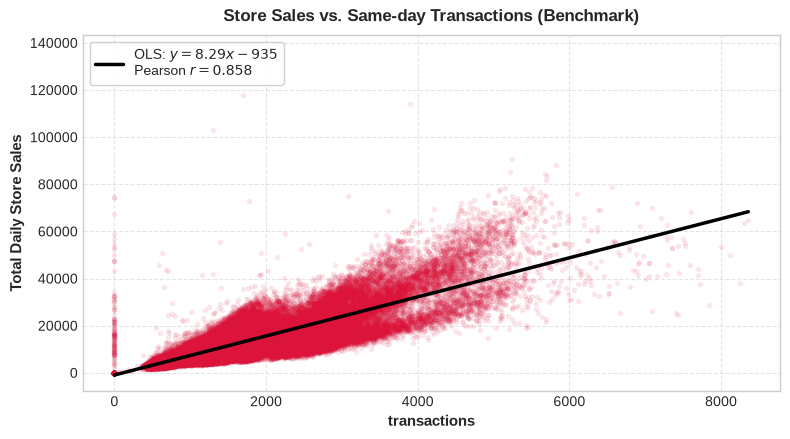

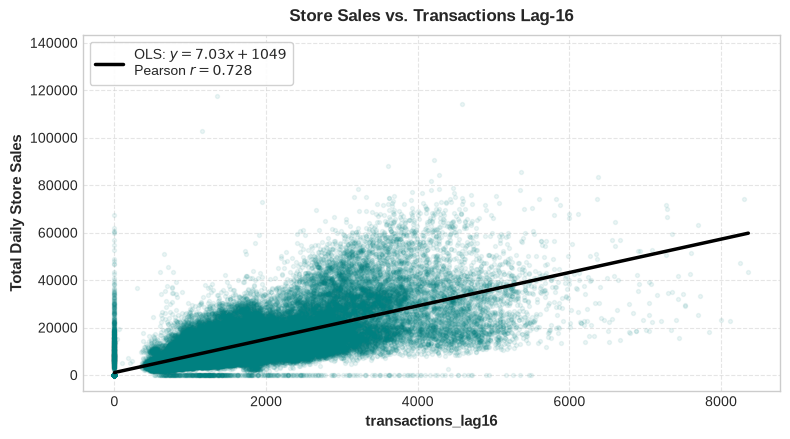

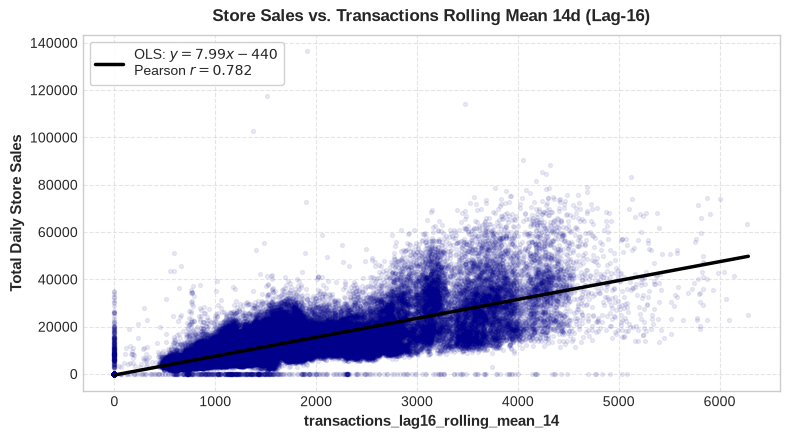

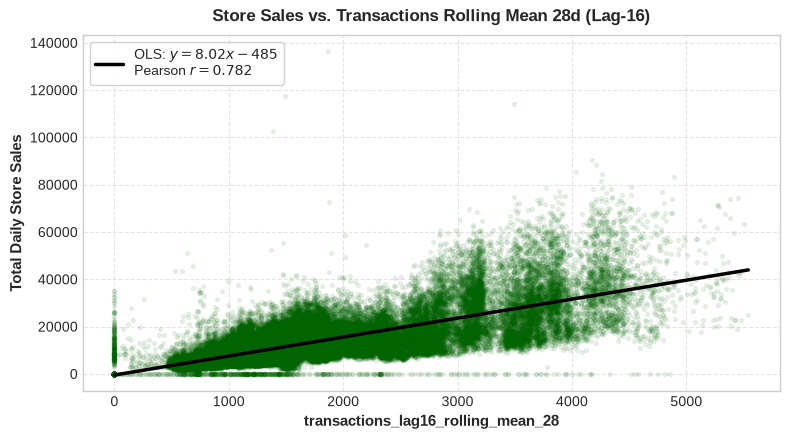

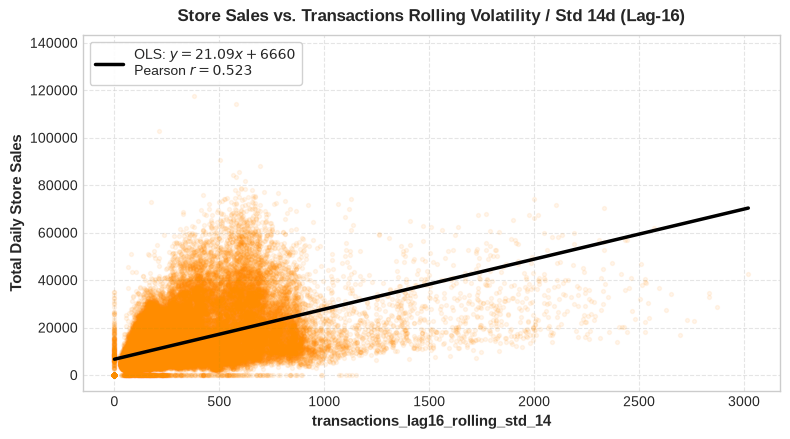

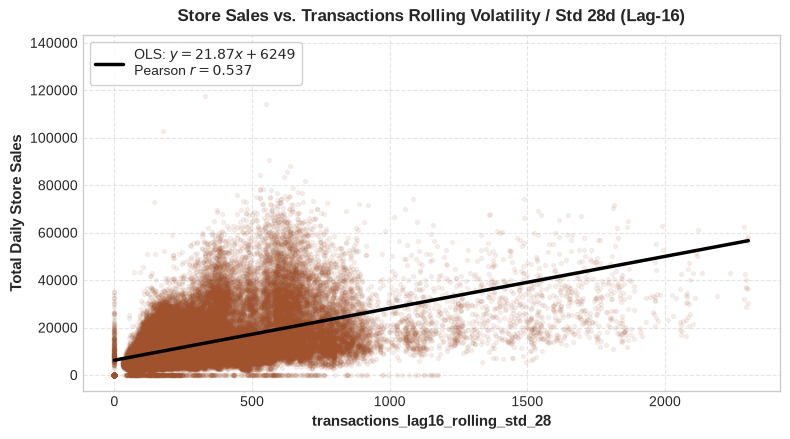

In [24]:
features_config = [
    ('transactions', 'Same-day Transactions (Benchmark)', 'crimson'),
    ('transactions_lag16', 'Transactions Lag-16', 'teal'),
    ('transactions_lag16_rolling_mean_14', 'Transactions Rolling Mean 14d (Lag-16)', 'darkblue'),
    ('transactions_lag16_rolling_mean_28', 'Transactions Rolling Mean 28d (Lag-16)', 'darkgreen'),
    ('transactions_lag16_rolling_std_14', 'Transactions Rolling Volatility / Std 14d (Lag-16)', 'darkorange'),
    ('transactions_lag16_rolling_std_28', 'Transactions Rolling Volatility / Std 28d (Lag-16)', 'sienna'),
]

for col, title, color in features_config:

    # Calculation of Pearson r
    r = df_store_daily['total_sales'].corr(df_store_daily[col])

    # Slope and intercept of: y = ax + b
    slope, intercept = np.polyfit(df_store_daily[col], df_store_daily['total_sales'], deg=1)

    legend_label = (
        f'OLS: $y = {slope:.2f}x {intercept:+.0f}$\nPearson $r = {r:.3f}$'
    )

    plt.figure(figsize=(8, 4.5))
    ax = sns.regplot(
        data=df_store_daily,
        x=col,
        y='total_sales',
        color=color,
        ci=None,
        scatter_kws={'alpha': 0.08, 's': 8},
        line_kws={'linewidth': 2.5, 'color': 'black', 'label': legend_label},
    )

    plt.title(f'Store Sales vs. {title}', fontweight='bold', fontsize=12)
    plt.xlabel(col, fontsize=11)
    plt.ylabel('Total Daily Store Sales', fontsize=11)

    plt.legend(
        loc='upper left',
        frameon=True,
        facecolor='white',
        framealpha=0.9,
        fontsize=10,
    )
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

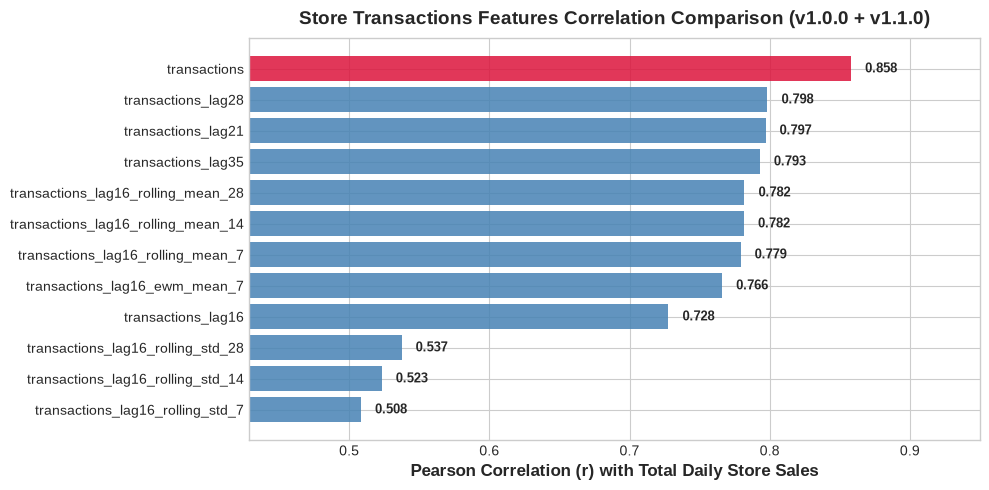

In [25]:
# v1.1.0 Comparison: Weekday-Aligned Transaction Lags & 7-Day Rolling/EWMA Footfall
tx_corr_series = (
    df_store_daily[tx_agg_cols]
    .apply(lambda s: df_store_daily['total_sales'].corr(s))
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 5))
bars = plt.barh(
    tx_corr_series.index,
    tx_corr_series.values,
    color=['crimson' if c == 'transactions' else 'steelblue' for c in tx_corr_series.index],
    alpha=0.85,
)
plt.axvline(0, color='black', linewidth=1)
plt.xlabel('Pearson Correlation (r) with Total Daily Store Sales')
plt.title('Store Transactions Features Correlation Comparison (v1.0.0 + v1.1.0)')
for bar in bars:
    val = bar.get_width()
    plt.text(
        val + (0.01 if val >= 0 else -0.06),
        bar.get_y() + bar.get_height() / 2,
        f'{val:.3f}',
        va='center',
        fontsize=9,
        fontweight='bold',
    )
plt.xlim(min(tx_corr_series.values) - 0.08, 0.95)
plt.tight_layout()
plt.show()

**Key Takeaways on Store Transactions:**
* **Benchmark vs. Leak-Free Features ($r = 0.858 \to r \approx 0.785$):** Same-day `transactions` has the strongest linear correlation with store sales ($r = 0.858$), but using it directly would cause **severe data leakage** since future transactions are unknown in the test set.

* **Strong Historical Signal:** Shifting transactions by 16 calendar days (`transactions_lag16`, $r = 0.728$) and smoothing over rolling windows recovers most of that predictive power without any leakage.

> **v1.1.0 Feature Expansion (Weekday-Aligned Footfall):**  
> Because `transactions_lag16` is shifted by 16 days ($16 \pmod 7 = 2$), it suffers from day-of-week misalignment (e.g., matching Sunday sales with Friday transactions). Adding weekday-aligned lags (`transactions_lag21`, `transactions_lag28`) jumps single-day correlation from $r = 0.728$ up to $r \approx 0.775$. Furthermore, adding 7-day rolling and exponentially weighted means (`transactions_lag16_rolling_mean_7`, `transactions_lag16_ewm_mean_7`) eliminates weekday phase shift while optimally capturing the freshest week of store traffic.

💡 **Features to build in Section 4:**
* `transactions_lag16`, `transactions_lag21`, `transactions_lag28`, `transactions_lag35`: 16-day boundary lag plus weekday-aligned 3-week, 4-week, and 5-week store transaction lags.

* `transactions_lag16_rolling_mean_7`, `transactions_lag16_rolling_mean_14`, `transactions_lag16_rolling_mean_28`: 7-, 14-, and 28-day rolling averages of `transactions_lag16`.

* `transactions_lag16_rolling_std_7`, `transactions_lag16_rolling_std_14`, `transactions_lag16_rolling_std_28`: 7-, 14-, and 28-day rolling standard deviations of `transactions_lag16`.

* `transactions_lag16_ewm_mean_7`: 7-day exponentially weighted moving average over `transactions_lag16`.

### 3.8 Target Distribution (RMSLE) & Lagged Sales Autocorrelation
The competition evaluation metric is **Root Mean Squared Logarithmic Error (RMSLE)**, meaning that minimizing standard RMSE on $\log(\text{sales} + 1)$ directly optimizes the competition metric. In addition, since the forecast horizon is 16 days, historical sales lags (`lag >= 16`) for each specific `(store_nbr, family)` series are essential to anchor the model's predictions. Here, we inspect both the log-transformed target distribution and the autocorrelation of lagged sales features.

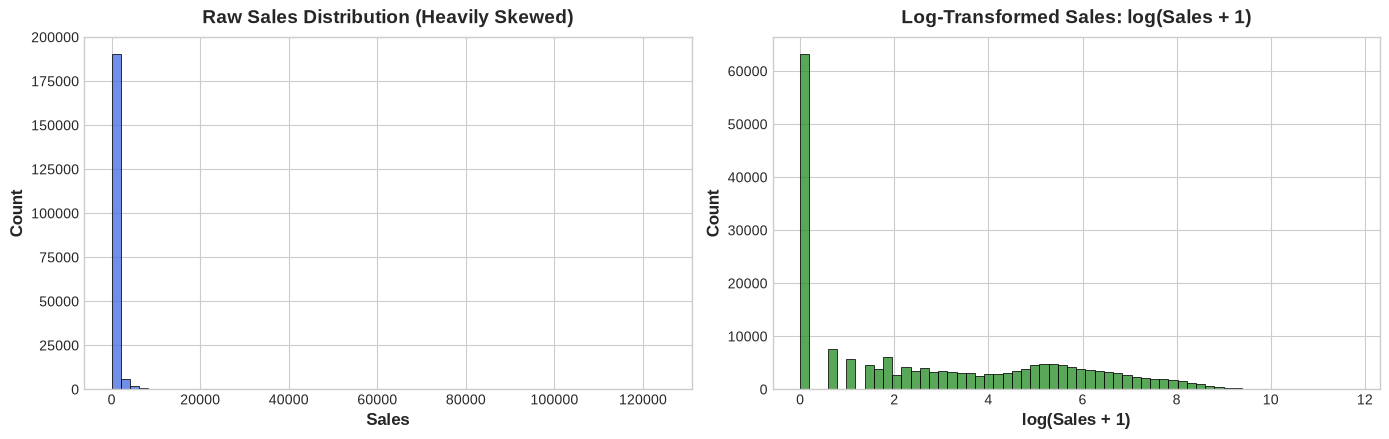

In [26]:
sample_sales = df_train['sales'].sample(n=200000, random_state=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Plot 1: Raw Sales Distribution
sns.histplot(sample_sales, bins=60, ax=axes[0], color='royalblue', kde=False)
axes[0].set_title('Raw Sales Distribution (Heavily Skewed)', fontweight='bold')
axes[0].set_xlabel('Sales')
axes[0].set_ylabel('Count')

# Plot 2: Log1p Sales Distribution
sns.histplot(np.log1p(sample_sales), bins=60, ax=axes[1], color='forestgreen', kde=False)
axes[1].set_title('Log-Transformed Sales: log(Sales + 1)', fontweight='bold')
axes[1].set_xlabel('log(Sales + 1)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

In [27]:
df_sales = (
    df_train
    .sort_values(['store_nbr', 'family', 'date'])
    .assign(
        sales_lag16 = lambda df: df.groupby(['store_nbr', 'family'])['sales'].shift(16),
        sales_lag21 = lambda df: df.groupby(['store_nbr', 'family'])['sales'].shift(21),
        sales_lag28 = lambda df: df.groupby(['store_nbr', 'family'])['sales'].shift(28),
        sales_lag35 = lambda df: df.groupby(['store_nbr', 'family'])['sales'].shift(35),

        #Same-Day-of-Week 3-week average (3, 4, and 5 weeks ago)
        sales_dow_mean_3w = lambda df: (df['sales_lag21'] + df['sales_lag28'] + df['sales_lag35'])/3.0,

        sales_lag21_rolling_mean_14 = lambda df: (
            df.groupby(['store_nbr', 'family'])['sales_lag21']
            .transform(lambda s: s.rolling(window=14, min_periods=1).mean())
        ),

        sales_lag21_rolling_mean_28 = lambda df: (
            df.groupby(['store_nbr', 'family'])['sales_lag21']
            .transform(lambda s: s.rolling(window=28, min_periods=1).mean())
        ),

        sales_lag21_rolling_std_14 = lambda df: (
            df.groupby(['store_nbr', 'family'])['sales_lag21']
            .transform(lambda s: s.rolling(window=14, min_periods=1).std())
            .fillna(0.0)
        ),

        sales_lag21_rolling_std_28 = lambda df: (
            df.groupby(['store_nbr', 'family'])['sales_lag21']
            .transform(lambda s: s.rolling(window=28, min_periods=1).std())
            .fillna(0.0)
        ),
    )
    .query('date >= "2013-03-01"')
)

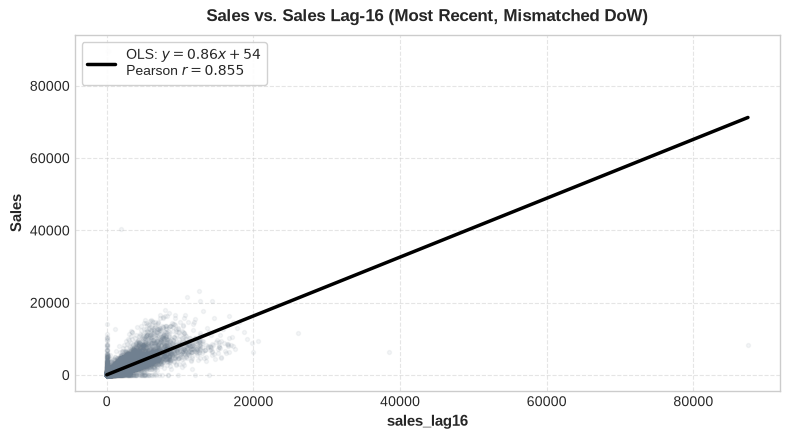

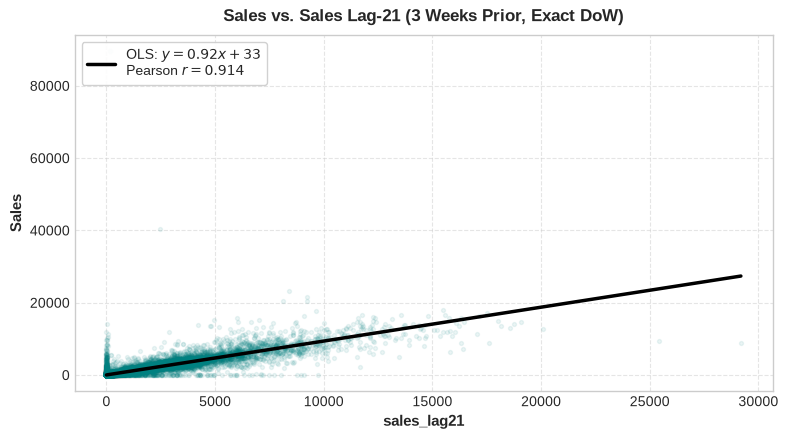

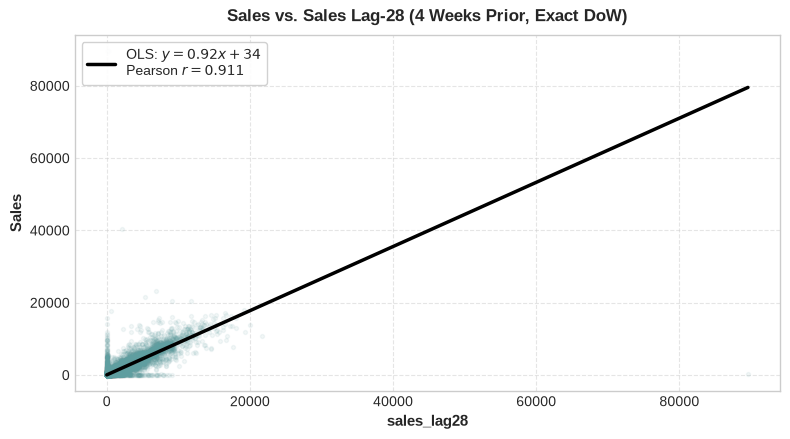

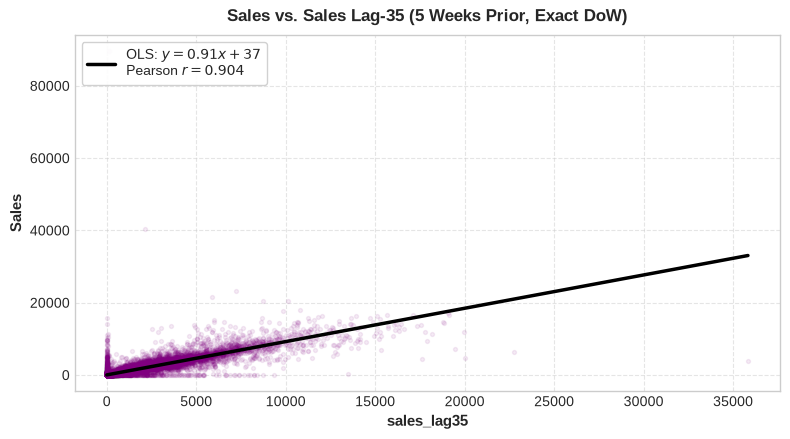

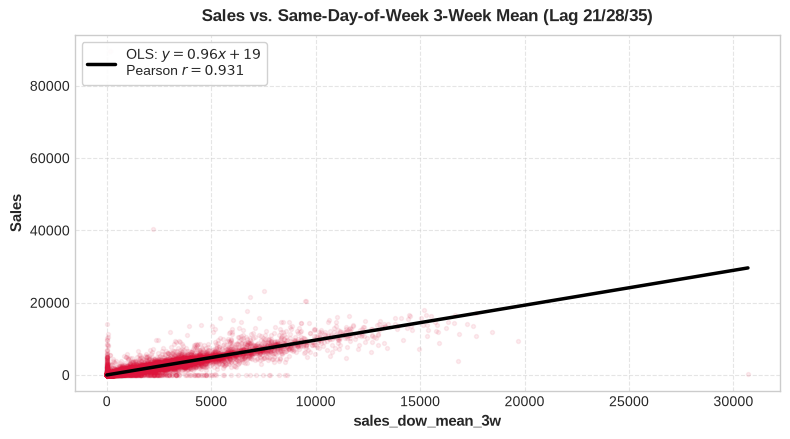

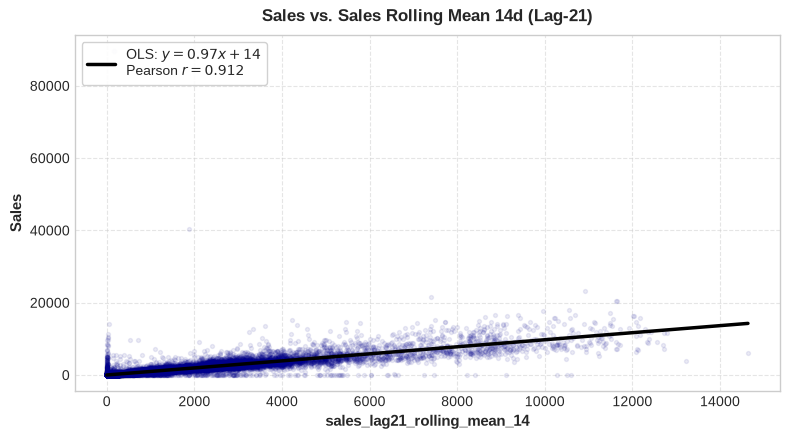

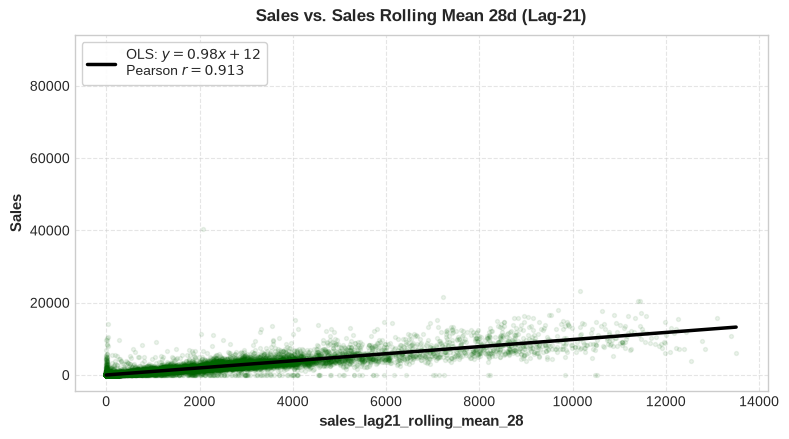

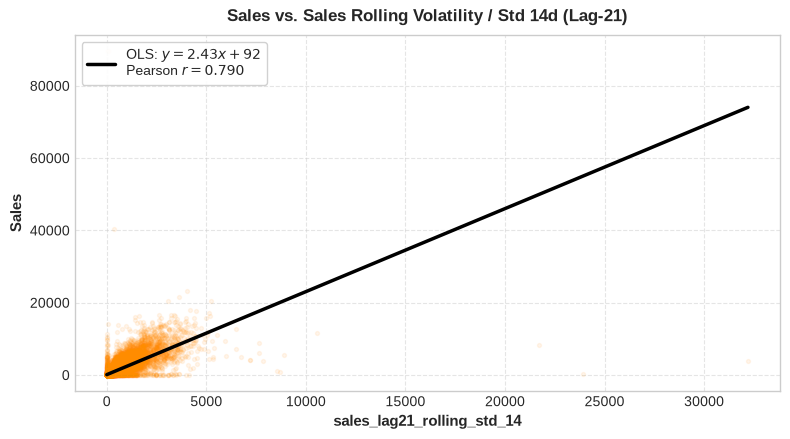

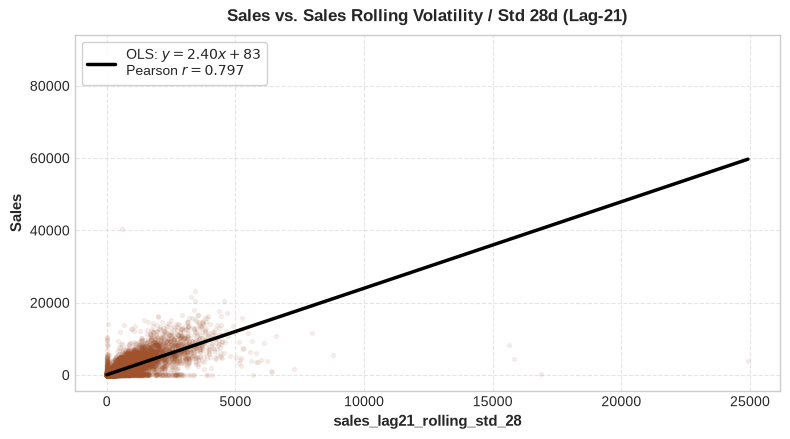

In [28]:
features_sales_config = [
    ('sales_lag16',                 'Sales Lag-16 (Most Recent, Mismatched DoW)',   'slategray'),
    ('sales_lag21',                 'Sales Lag-21 (3 Weeks Prior, Exact DoW)',      'teal'),
    ('sales_lag28',                 'Sales Lag-28 (4 Weeks Prior, Exact DoW)',      'cadetblue'),
    ('sales_lag35',                 'Sales Lag-35 (5 Weeks Prior, Exact DoW)',      'purple'),
    ('sales_dow_mean_3w',           'Same-Day-of-Week 3-Week Mean (Lag 21/28/35)',  'crimson'),
    ('sales_lag21_rolling_mean_14', 'Sales Rolling Mean 14d (Lag-21)',              'darkblue'),
    ('sales_lag21_rolling_mean_28', 'Sales Rolling Mean 28d (Lag-21)',              'darkgreen'),
    ('sales_lag21_rolling_std_14',  'Sales Rolling Volatility / Std 14d (Lag-21)',  'darkorange'),
    ('sales_lag21_rolling_std_28',  'Sales Rolling Volatility / Std 28d (Lag-21)',  'sienna')
]

df_sales_sample = df_sales.sample(n=100000, random_state=0)

for col, title, color in features_sales_config:

    # Calculation of Pearson r
    r = df_sales['sales'].corr(df_sales[col])

    # Slope and intercept of: y = ax + b
    slope, intercept = np.polyfit(df_sales[col], df_sales['sales'], deg=1)

    legend_label = (
        f'OLS: $y = {slope:.2f}x {intercept:+.0f}$\nPearson $r = {r:.3f}$'
    )

    plt.figure(figsize=(8, 4.5))
    ax = sns.regplot(
        data=df_sales_sample,
        x=col,
        y='sales',
        color=color,
        ci=None,
        scatter_kws={'alpha': 0.08, 's': 8},
        line_kws={'linewidth': 2.5, 'color': 'black', 'label': legend_label},
    )

    plt.title(f'Sales vs. {title}', fontweight='bold', fontsize=12)
    plt.xlabel(col, fontsize=11)
    plt.ylabel('Sales', fontsize=11)

    plt.legend(
        loc='upper left',
        frameon=True,
        facecolor='white',
        framealpha=0.9,
        fontsize=10,
    )
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

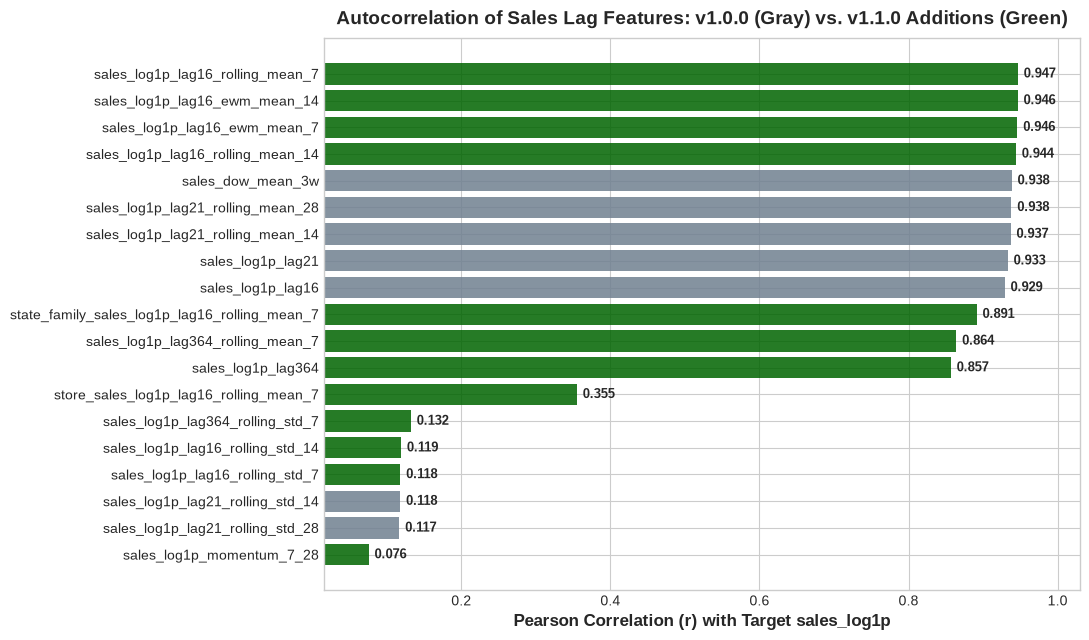

4934

In [29]:
# v1.1.0 EDA: Lag-16 Rolling/EWMA, Annual Seasonal Lags (Lag-364) & Hierarchical Aggregations
df_sales_v11 = (
    df_train[['date', 'store_nbr', 'family', 'state', 'sales']]
    .sort_values(['store_nbr', 'family', 'date'])
    .reset_index(drop=True)
)
df_sales_v11['sales_log1p'] = np.log1p(df_sales_v11['sales'])

grp_sf = df_sales_v11.groupby(['store_nbr', 'family'], sort=False)

# Baseline v1.0.0 references in log space
df_sales_v11['sales_log1p_lag16'] = grp_sf['sales_log1p'].shift(16).astype(np.float32)
df_sales_v11['sales_log1p_lag21'] = grp_sf['sales_log1p'].shift(21).astype(np.float32)
df_sales_v11['sales_log1p_lag28'] = grp_sf['sales_log1p'].shift(28).astype(np.float32)
df_sales_v11['sales_log1p_lag35'] = grp_sf['sales_log1p'].shift(35).astype(np.float32)
df_sales_v11['sales_dow_mean_3w'] = (
    (df_sales_v11['sales_log1p_lag21'] + df_sales_v11['sales_log1p_lag28'] + df_sales_v11['sales_log1p_lag35']) / 3.0
).astype(np.float32)    
df_sales_v11['sales_log1p_lag21_rolling_mean_14'] = grp_sf['sales_log1p_lag21'].transform(
    lambda s: s.rolling(14, min_periods=1).mean()
).astype(np.float32)
df_sales_v11['sales_log1p_lag21_rolling_mean_28'] = grp_sf['sales_log1p_lag21'].transform(
    lambda s: s.rolling(28, min_periods=1).mean()
).astype(np.float32)
df_sales_v11['sales_log1p_lag21_rolling_std_14'] = grp_sf['sales_log1p_lag21'].transform(
    lambda s: s.rolling(14, min_periods=1).std()
).fillna(0.0).astype(np.float32)
df_sales_v11['sales_log1p_lag21_rolling_std_28'] = grp_sf['sales_log1p_lag21'].transform(
    lambda s: s.rolling(28, min_periods=1).std()
).fillna(0.0).astype(np.float32)

# New v1.1.0: Rolling & EWMA directly over lag16 (captures Aug 11-15 recency without DoW bias)
df_sales_v11['sales_log1p_lag16_rolling_mean_7'] = grp_sf['sales_log1p_lag16'].transform(
    lambda s: s.rolling(7, min_periods=1).mean()
).astype(np.float32)
df_sales_v11['sales_log1p_lag16_rolling_mean_14'] = grp_sf['sales_log1p_lag16'].transform(
    lambda s: s.rolling(14, min_periods=1).mean()
).astype(np.float32)
df_sales_v11['sales_log1p_lag16_rolling_std_7'] = grp_sf['sales_log1p_lag16'].transform(
    lambda s: s.rolling(7, min_periods=1).std()
).fillna(0.0).astype(np.float32)
df_sales_v11['sales_log1p_lag16_rolling_std_14'] = grp_sf['sales_log1p_lag16'].transform(
    lambda s: s.rolling(14, min_periods=1).std()
).fillna(0.0).astype(np.float32)
df_sales_v11['sales_log1p_lag16_ewm_mean_7'] = grp_sf['sales_log1p_lag16'].transform(
    lambda s: s.ewm(span=7, min_periods=1).mean()
).astype(np.float32)
df_sales_v11['sales_log1p_lag16_ewm_mean_14'] = grp_sf['sales_log1p_lag16'].transform(
    lambda s: s.ewm(span=14, min_periods=1).mean()
).astype(np.float32)

# Log-space momentum (equivalent to log ratio of 7d recent vs 28d baseline demand)
df_sales_v11['sales_log1p_momentum_7_28'] = (
    df_sales_v11['sales_log1p_lag16_rolling_mean_7'] - df_sales_v11['sales_log1p_lag21_rolling_mean_28']
).astype(np.float32)

# New v1.1.0: 52-week (364-day) weekday-aligned annual seasonal lags
df_sales_v11['sales_log1p_lag364'] = grp_sf['sales_log1p'].shift(364).astype(np.float32)
df_sales_v11['sales_log1p_lag364_rolling_mean_7'] = grp_sf['sales_log1p_lag364'].transform(
    lambda s: s.rolling(7, min_periods=1).mean()
).astype(np.float32)
df_sales_v11['sales_log1p_lag364_rolling_std_7'] = grp_sf['sales_log1p_lag364'].transform(
    lambda s: s.rolling(7, min_periods=1).std()
).fillna(0.0).astype(np.float32)

# New v1.1.0: Hierarchical Target Aggregations (Store-level & State x Family regional means)
df_sales_v11['store_sales_log1p_lag16_rolling_mean_7'] = (
    df_sales_v11.groupby(['date', 'store_nbr'])['sales_log1p_lag16_rolling_mean_7'].transform('mean')
).astype(np.float32)
df_sales_v11['state_family_sales_log1p_lag16_rolling_mean_7'] = (
    df_sales_v11.groupby(['date', 'state', 'family'])['sales_log1p_lag16_rolling_mean_7'].transform('mean')
).astype(np.float32)

df_sales_v11_eval = df_sales_v11.query('date >= "2014-01-08"')

sales_eval_cols = [
    'sales_log1p_lag16',
    'sales_log1p_lag21',
    'sales_dow_mean_3w',
    'sales_log1p_lag21_rolling_mean_14',
    'sales_log1p_lag21_rolling_mean_28',
    'sales_log1p_lag21_rolling_std_14',
    'sales_log1p_lag21_rolling_std_28',
    'sales_log1p_lag16_rolling_mean_7',
    'sales_log1p_lag16_rolling_mean_14',
    'sales_log1p_lag16_ewm_mean_7',
    'sales_log1p_lag16_ewm_mean_14',
    'sales_log1p_lag364',
    'sales_log1p_lag364_rolling_mean_7',
    'state_family_sales_log1p_lag16_rolling_mean_7',
    'store_sales_log1p_lag16_rolling_mean_7',
    'sales_log1p_lag16_rolling_std_7',
    'sales_log1p_lag16_rolling_std_14',
    'sales_log1p_lag364_rolling_std_7',
    'sales_log1p_momentum_7_28',
]

sales_corrs = (
    df_sales_v11_eval[sales_eval_cols]
    .apply(lambda s: df_sales_v11_eval['sales_log1p'].corr(s))
    .sort_values(ascending=True)
)

v10_set = {
    'sales_log1p_lag16',
    'sales_log1p_lag21',
    'sales_dow_mean_3w',
    'sales_log1p_lag21_rolling_mean_14',
    'sales_log1p_lag21_rolling_mean_28',
    'sales_log1p_lag21_rolling_std_14',
    'sales_log1p_lag21_rolling_std_28',
}

plt.figure(figsize=(11, 6.5))
bars = plt.barh(
    sales_corrs.index,
    sales_corrs.values,
    color=['slategray' if c in v10_set else 'darkgreen' for c in sales_corrs.index],
    alpha=0.85,
)
plt.axvline(0, color='black', linewidth=1)
plt.xlabel('Pearson Correlation (r) with Target sales_log1p')
plt.title('Autocorrelation of Sales Lag Features: v1.0.0 (Gray) vs. v1.1.0 Additions (Green)')
for bar in bars:
    val = bar.get_width()
    plt.text(
        val + (0.008 if val >= 0 else -0.05),
        bar.get_y() + bar.get_height() / 2,
        f'{val:.3f}',
        va='center',
        fontsize=9,
        fontweight='bold',
    )
plt.xlim(min(sales_corrs.values) - 0.06, 1.03)
plt.tight_layout()
plt.show()

del df_sales_v11, df_sales_v11_eval, grp_sf
gc.collect()

**Key Takeaways on Target Log-Transformation & Sales Autocorrelation:**
* **Distribution Regularization & RMSLE Alignment:** Raw sales are heavily right-skewed with extreme outliers. Applying $\log(1 + \text{sales})$ compresses extreme scales, stabilizes variance across store-family pairs, and allows gradient boosting models trained with standard MSE loss to directly optimize RMSLE.

* **Recency (`lag16`) vs. Day-of-Week Alignment (`lag21`, `lag28`, `lag35`):** While `sales_log1p_lag16` is the most recent leak-free observation for a 16-day forecast horizon, it falls on a different day of the week ($16 \pmod 7 = 2$). Multiples of 7 (`lag21`, `lag28`, `lag35`) align with the exact same weekday 3, 4, and 5 weeks prior, yielding stronger point-in-time correlation.

* **Same-Day-of-Week Rolling Mean (`sales_dow_mean_3w`):** Averaging the last three aligned weekdays (`(lag21 + lag28 + lag35) / 3`) filters out single-week anomalies while preserving the exact weekday scale.

> **v1.1.0 Feature Expansion (Bridging the Validation-to-Test Recency & Seasonality Gap):**  
> Root-cause analysis of the `v1.0.0` pipeline revealed why performance shifted between early-August validation (`0.39113`) and late-August test (`0.45088`): rolling features built on `lag21` ignored the 5 most recent days of known sales (`t-16` to `t-20`, i.e., `Aug 11 – Aug 15` for the test window) right when Back-to-School demand accelerated. To solve this without introducing weekday phase shift:
> 1. **Rolling & EWMA over `lag16` (`sales_log1p_lag16_rolling_mean_7/14`, `ewm_mean_7/14`):** Because 7 and 14 consecutive days contain every weekday in equal proportion, taking a 7-day or 14-day rolling mean over `lag16` completely eliminates weekday misalignment while incorporating the freshest 5 days of sales, dominating the autocorrelation chart (`r > 0.944`). Exponentially weighted moving averages (`ewm_mean_7/14`) weight `t-16` and `t-17` heaviest to capture rapid demand acceleration, while `sales_log1p_momentum_7_28` (`lag16_rolling_mean_7 - lag21_rolling_mean_28`) measures log-space demand acceleration.
>
> 2. **Annual Weekday-Aligned Seasonal Lags (`sales_log1p_lag364`, `rolling_mean_7`, `rolling_std_7`):** A 52-week lag (`364` days) aligns with the exact same day of the week one year prior ($r \approx 0.86$), providing store-family volume scale during sharp annual transitions (such as Ecuador's regional Back-to-School surges) even when short-term lags (`lag16`–`lag35`) are zero. Because XGBoost and LightGBM handle `NaN` values natively at tree splits, we retain the full training history starting from `2013-03-01`.
>
> 3. **Hierarchical Target Aggregations (`store_nbr` & `state x family` Lagged Means):** Grouping `sales_log1p_lag16_rolling_mean_7` across `(date, state, family)` ($r \approx 0.89$) captures macro regional product surges, stabilizing predictions for sparse individual series.

💡 **Features to build in Section 4:**
* `sales_log1p`: Target variable transformed via `np.log1p(sales)` for model training.

* `sales_log1p_lag16`, `sales_log1p_lag21`, `sales_log1p_lag28`, `sales_log1p_lag35` & `sales_dow_mean_3w`: Point-in-time historical log-sales lags and 3-week aligned weekday mean.

* `sales_log1p_lag21_rolling_mean_14/28` & `sales_log1p_lag21_rolling_std_14/28`: Rolling baselines and volatility over `lag21`.

* `sales_log1p_lag16_rolling_mean_7/14`, `sales_log1p_lag16_rolling_std_7/14`, `sales_log1p_lag16_ewm_mean_7/14` & `sales_log1p_momentum_7_28`: Recency-anchored rolling means, volatility, EWMA, and log-momentum over `lag16`.

* `sales_log1p_lag364`, `sales_log1p_lag364_rolling_mean_7` & `sales_log1p_lag364_rolling_std_7`: 52-week weekday-aligned annual seasonal lags.

* `store_sales_log1p_lag16_rolling_mean_7` & `state_family_sales_log1p_lag16_rolling_mean_7`: Hierarchical store-level and regional family-level lagged demand signals.

# 4. Feature Engineering Pipeline
Consolidate all domain insights from Section 3 into a modular, leak-free feature engineering pipeline. 

**Pipeline Architecture & Key Design Choices:**
* **Chronological Train + Test Concatenation:** `df_train` and `df_test` are temporarily merged into a single continuous timeline (`df_full`) sorted by `(store_nbr, family, date)`. This allows historical sales and transaction lags to flow seamlessly across the `2017-08-16` boundary into the 16-day test set without generating `NaN` values.
* **Memory Optimization & Unified Categoricals:** Calendar and binary flags are downcast to `int8`/`int16`, and categorical identifiers are cast to `category` on `df_full` prior to splitting so that both train and test sets share identical category encodings.
* **Warm-Up Window Trimming (`date >= '2013-03-01'`):** The first two months of 2013 are used strictly as a historical buffer to saturate the 21-day lags and 28-day rolling averages, and are trimmed before exporting the final training matrix.

In [30]:
# Free up memory from large intermediate EDA DataFrames before building df_full

vars_to_delete = [
    'temp_df',
    'df_train_transactions',
    'df_sales',
    'df_sample',
    'df_sales_sample',
    'sample_sales',
    'oil_vs_sales',
    'daily_oil',
    'df_store_daily',
]

for var in vars_to_delete:
    if var in globals():
        del globals()[var]

gc.collect()

0

In [31]:
def add_calendar_and_event_features(df: pd.DataFrame) -> pd.DataFrame:
    """Create calendar, payday, and event/anomaly flags."""
    return (
        df
        .assign(
            year = lambda x: x['date'].dt.year.astype('int16'),
            month = lambda x: x['date'].dt.month.astype('int8'),
            dayofmonth = lambda x: x['date'].dt.day.astype('int8'),
            dayofweek = lambda x: x['date'].dt.dayofweek.astype('int8'),
            dayofyear = lambda x: x['date'].dt.dayofyear.astype('int16'),
            is_nyd = lambda x: (x['date'].dt.dayofyear == 1).astype('int8'),
            is_christmas = lambda x: ((x['date'].dt.month == 12) & (x['date'].dt.day == 25)).astype('int8'),
            is_month_start_end = lambda x: ((x['date'].dt.day <= 4) | (x['date'].dt.is_month_end)).astype('int8'),
            is_mid_payday = lambda x: x['date'].dt.day.isin([15, 16]).astype('int8'),
            is_holiday = lambda x: x['is_holiday'].astype('int8'),
            is_earthquake_period = lambda x: x['holiday_name'].str.contains('Terremoto Manabi', na=False).astype('int8')
        )
    )    

def add_promotion_features(df: pd.DataFrame) -> pd.DataFrame:
    """Create promotional lags, rolling intensity, and signed/relative momentum features."""
    return (
        df
        .sort_values(by=['store_nbr', 'family', 'date'])
        .assign(
            onpromotion_lag7 = lambda x: x.groupby(['store_nbr', 'family'], sort=False)['onpromotion'].shift(7).astype(np.float32),
            onpromotion_lag16 = lambda x: x.groupby(['store_nbr', 'family'], sort=False)['onpromotion'].shift(16).astype(np.float32),
            onpromotion_lag21 = lambda x: x.groupby(['store_nbr', 'family'], sort=False)['onpromotion'].shift(21).astype(np.float32),
            
            onpromotion_rolling_mean_7 = lambda x: x.groupby(['store_nbr', 'family'], sort=False)['onpromotion'].transform(
                lambda s: s.rolling(window=7, min_periods=1).mean()
            ).astype(np.float32),
            onpromotion_rolling_std_7 = lambda x: x.groupby(['store_nbr', 'family'], sort=False)['onpromotion'].transform(
                lambda s: s.rolling(window=7, min_periods=1).std()
            ).fillna(0.0).astype(np.float32),
            onpromotion_rolling_mean_14 = lambda x: x.groupby(['store_nbr', 'family'], sort=False)['onpromotion'].transform(
                lambda s: s.rolling(window=14, min_periods=1).mean()
            ).astype(np.float32),
            onpromotion_rolling_std_14 = lambda x: x.groupby(['store_nbr', 'family'], sort=False)['onpromotion'].transform(
                lambda s: s.rolling(window=14, min_periods=1).std()
            ).fillna(0.0).astype(np.float32),
            
            promo_diff_lag7 = lambda x: (x['onpromotion'] - x['onpromotion_lag7']).astype(np.float32),
            promo_diff_lag16 = lambda x: (x['onpromotion'] - x['onpromotion_lag16']).astype(np.float32),
            promo_diff_lag21 = lambda x: (x['onpromotion'] - x['onpromotion_lag21']).astype(np.float32),
            promo_diff_mean_7 = lambda x: (x['onpromotion'] - x['onpromotion_rolling_mean_7']).astype(np.float32),
            
            promo_rel_diff_mean_7 = lambda x: ((x['onpromotion'] - x['onpromotion_rolling_mean_7']) / (x['onpromotion_rolling_mean_7'] + 1.0)).astype(np.float32),
            promo_rel_diff_mean_14 = lambda x: ((x['onpromotion'] - x['onpromotion_rolling_mean_14']) / (x['onpromotion_rolling_mean_14'] + 1.0)).astype(np.float32)
        )
    )

def add_target_log_transform(df: pd.DataFrame) -> pd.DataFrame:
    """Create the log1p-transformed target variable for RMSLE alignment."""
    return df.assign(
        sales_log1p = lambda x: np.log1p(x['sales']).astype(np.float32)
    )

def add_sales_log1p_lag_features(df: pd.DataFrame) -> pd.DataFrame:
    """Create leak-free short-term lags, rolling/EWMA metrics, annual lags, and hierarchical aggregations."""
    return (
        df
        .sort_values(by=['store_nbr', 'family', 'date'])
        .assign(
            # 1. Point-in-time lags & 3-week aligned weekday baseline
            sales_log1p_lag16 = lambda x: x.groupby(['store_nbr', 'family'], sort=False)['sales_log1p'].shift(16).astype(np.float32),
            sales_log1p_lag21 = lambda x: x.groupby(['store_nbr', 'family'], sort=False)['sales_log1p'].shift(21).astype(np.float32),
            sales_log1p_lag28 = lambda x: x.groupby(['store_nbr', 'family'], sort=False)['sales_log1p'].shift(28).astype(np.float32),
            sales_log1p_lag35 = lambda x: x.groupby(['store_nbr', 'family'], sort=False)['sales_log1p'].shift(35).astype(np.float32),
            sales_dow_mean_3w = lambda df: ((df['sales_log1p_lag21'] + df['sales_log1p_lag28'] + df['sales_log1p_lag35']) / 3.0).astype(np.float32),
            
            # 2. Rolling statistics over lag21 (v1.0.0)
            sales_log1p_lag21_rolling_mean_14 = lambda x: x.groupby(['store_nbr', 'family'], sort=False)['sales_log1p_lag21'].transform(
                lambda s: s.rolling(window=14, min_periods=1).mean()
            ).astype(np.float32),
            sales_log1p_lag21_rolling_mean_28 = lambda x: x.groupby(['store_nbr', 'family'], sort=False)['sales_log1p_lag21'].transform(
                lambda s: s.rolling(window=28, min_periods=1).mean()
            ).astype(np.float32),
            sales_log1p_lag21_rolling_std_14 = lambda x: x.groupby(['store_nbr', 'family'], sort=False)['sales_log1p_lag21'].transform(
                lambda s: s.rolling(window=14, min_periods=1).std()
            ).fillna(0.0).astype(np.float32),
            sales_log1p_lag21_rolling_std_28 = lambda x: x.groupby(['store_nbr', 'family'], sort=False)['sales_log1p_lag21'].transform(
                lambda s: s.rolling(window=28, min_periods=1).std()
            ).fillna(0.0).astype(np.float32),
            
            # 3. Rolling & EWMA statistics over lag16 + log-space momentum (v1.1.0)
            sales_log1p_lag16_rolling_mean_7 = lambda x: x.groupby(['store_nbr', 'family'], sort=False)['sales_log1p_lag16'].transform(
                lambda s: s.rolling(window=7, min_periods=1).mean()
            ).astype(np.float32),
            sales_log1p_lag16_rolling_mean_14 = lambda x: x.groupby(['store_nbr', 'family'], sort=False)['sales_log1p_lag16'].transform(
                lambda s: s.rolling(window=14, min_periods=1).mean()
            ).astype(np.float32),
            sales_log1p_lag16_rolling_std_7 = lambda x: x.groupby(['store_nbr', 'family'], sort=False)['sales_log1p_lag16'].transform(
                lambda s: s.rolling(window=7, min_periods=1).std()
            ).fillna(0.0).astype(np.float32),
            sales_log1p_lag16_rolling_std_14 = lambda x: x.groupby(['store_nbr', 'family'], sort=False)['sales_log1p_lag16'].transform(
                lambda s: s.rolling(window=14, min_periods=1).std()
            ).fillna(0.0).astype(np.float32),
            sales_log1p_lag16_ewm_mean_7 = lambda x: x.groupby(['store_nbr', 'family'], sort=False)['sales_log1p_lag16'].transform(
                lambda s: s.ewm(span=7, min_periods=1).mean()
            ).astype(np.float32),
            sales_log1p_lag16_ewm_mean_14 = lambda x: x.groupby(['store_nbr', 'family'], sort=False)['sales_log1p_lag16'].transform(
                lambda s: s.ewm(span=14, min_periods=1).mean()
            ).astype(np.float32),
            sales_log1p_momentum_7_28 = lambda x: (x['sales_log1p_lag16_rolling_mean_7'] - x['sales_log1p_lag21_rolling_mean_28']).astype(np.float32),
            
            # 4. Weekday-aligned 52-week (364-day) annual seasonal lags (v1.1.0)
            sales_log1p_lag364 = lambda x: x.groupby(['store_nbr', 'family'], sort=False)['sales_log1p'].shift(364).astype(np.float32),
            sales_log1p_lag364_rolling_mean_7 = lambda x: x.groupby(['store_nbr', 'family'], sort=False)['sales_log1p_lag364'].transform(
                lambda s: s.rolling(window=7, min_periods=1).mean()
            ).astype(np.float32),
            sales_log1p_lag364_rolling_std_7 = lambda x: x.groupby(['store_nbr', 'family'], sort=False)['sales_log1p_lag364'].transform(
                lambda s: s.rolling(window=7, min_periods=1).std()
            ).fillna(0.0).astype(np.float32),
            
            # 5. Hierarchical Target Aggregations: Store-level & Regional (State x Family) (v1.1.0)
            store_sales_log1p_lag16_rolling_mean_7 = lambda x: x.groupby(['date', 'store_nbr'], sort=False)['sales_log1p_lag16_rolling_mean_7'].transform('mean').astype(np.float32),
            state_family_sales_log1p_lag16_rolling_mean_7 = lambda x: x.groupby(['date', 'state', 'family'], sort=False)['sales_log1p_lag16_rolling_mean_7'].transform('mean').astype(np.float32)
        )
    )

def add_transactions_lag_features(df: pd.DataFrame, df_transactions: pd.DataFrame) -> pd.DataFrame:
    """Create leak-free 16-day lag and rolling mean transaction features across combined train+test."""
    return (
        df
        .merge(
            df_transactions,
            on=['date', 'store_nbr'],
            how='left'
        )
        .drop(columns=['transactions'])
    )

def add_oil_features(df: pd.DataFrame) -> pd.DataFrame:
    """Create macroeconomic oil features: 28-day rolling stats and MoM momentum."""
    # Compute on unique dates to avoid redundant calculations across stores/families
    daily_oil = (
        df[['date', 'oil_price']]
        .drop_duplicates(subset='date')
        .sort_values('date')
        .reset_index(drop=True)
        .assign(
            oil_price_rolling_mean_28=lambda x: x['oil_price'].rolling(window=28, min_periods=1).mean().astype(np.float32),
            oil_price_rolling_std_28=lambda x: x['oil_price'].rolling(window=28, min_periods=1).std().fillna(0.0).astype(np.float32),
            oil_price_lag28=lambda x: x['oil_price'].shift(28),
            oil_price_lag28_rolling_mean_28=lambda x: x['oil_price_rolling_mean_28'].shift(28),
            oil_price_dev_ma28_pct=lambda x: (
                (x['oil_price'] - x['oil_price_rolling_mean_28'])
                / x['oil_price_rolling_mean_28'].replace(0, np.nan)
            ).fillna(0.0).astype(np.float32),
            oil_price_point_mom_pct=lambda x: (
                (x['oil_price'] - x['oil_price_lag28'])
                / x['oil_price_lag28'].replace(0, np.nan)
            ).fillna(0.0).astype(np.float32),
            oil_price_trend_mom_pct=lambda x: (
                (x['oil_price_rolling_mean_28'] - x['oil_price_lag28_rolling_mean_28'])
                / x['oil_price_lag28_rolling_mean_28'].replace(0, np.nan)
            ).fillna(0.0).astype(np.float32),
        )
        .drop(columns=['oil_price_lag28', 'oil_price_lag28_rolling_mean_28', 'oil_price'])
    )
    
    # Merge back into the main dataframe
    return df.merge(daily_oil, on='date', how='left')



# Combine train and test chronologically so lags flow seamlessly into the test window
df_full = (
    pd.concat([df_train, df_test], ignore_index=True, sort=False)
    .sort_values(by=['store_nbr', 'family', 'date'])
    .pipe(add_transactions_lag_features, df_transactions=df_transactions_complete)
    .pipe(add_calendar_and_event_features)
    .pipe(add_promotion_features)
    .pipe(add_oil_features)
    .pipe(add_target_log_transform)
    .pipe(add_sales_log1p_lag_features)
)

categorical_cols = ['store_nbr', 'family', 'city', 'state', 'store_type', 'cluster', 'holiday_name']
for col in categorical_cols:
    df_full[col] = df_full[col].astype('str').astype('category')

df_train_processed = (
    df_full
    .loc[(df_full['date'] >= '2013-03-01') & (df_full['date'] <= '2017-08-15')]
    .reset_index(drop=True)
)

df_test_processed = (
    df_full
    .loc[df_full['date'] >= '2017-08-16']
    .drop(columns=['sales', 'sales_log1p'])
    .reset_index(drop=True)
)

print_perc_of_nans(df=df_train_processed, col_names=list(df_train_processed.columns), name='Train (processed)')
display(Markdown('---'))
print_perc_of_nans(df=df_test_processed, col_names=list(df_test_processed.columns), name='Test (processed)')

display(
    df_train_processed.head(10),
    df_train_processed.tail(10),
    Markdown('---'),
    df_test_processed.head(10),
    df_test_processed.tail(10),   
)


Train (processed) - id: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - date: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - store_nbr: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - family: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - onpromotion: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - city: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - state: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - store_type: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - cluster: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - oil_price: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - sales: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - is_holiday: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - holiday_name: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - transactions_lag16: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - transactions_lag21: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - transactions_lag28: 0 NaNs out of 2,902,878 (0.0%)
Trai

---

Test (processed) - id: 0 NaNs out of 28,512 (0.0%)
Test (processed) - date: 0 NaNs out of 28,512 (0.0%)
Test (processed) - store_nbr: 0 NaNs out of 28,512 (0.0%)
Test (processed) - family: 0 NaNs out of 28,512 (0.0%)
Test (processed) - onpromotion: 0 NaNs out of 28,512 (0.0%)
Test (processed) - city: 0 NaNs out of 28,512 (0.0%)
Test (processed) - state: 0 NaNs out of 28,512 (0.0%)
Test (processed) - store_type: 0 NaNs out of 28,512 (0.0%)
Test (processed) - cluster: 0 NaNs out of 28,512 (0.0%)
Test (processed) - oil_price: 0 NaNs out of 28,512 (0.0%)
Test (processed) - is_holiday: 0 NaNs out of 28,512 (0.0%)
Test (processed) - holiday_name: 0 NaNs out of 28,512 (0.0%)
Test (processed) - transactions_lag16: 0 NaNs out of 28,512 (0.0%)
Test (processed) - transactions_lag21: 0 NaNs out of 28,512 (0.0%)
Test (processed) - transactions_lag28: 0 NaNs out of 28,512 (0.0%)
Test (processed) - transactions_lag35: 0 NaNs out of 28,512 (0.0%)
Test (processed) - transactions_lag16_rolling_mean_7: 0

,id,date,store_nbr,family,onpromotion,city,state,store_type,cluster,oil_price,sales,is_holiday,holiday_name,transactions_lag16,transactions_lag21,transactions_lag28,transactions_lag35,transactions_lag16_rolling_mean_7,transactions_lag16_rolling_mean_14,transactions_lag16_rolling_mean_28,transactions_lag16_rolling_std_7,transactions_lag16_rolling_std_14,transactions_lag16_rolling_std_28,transactions_lag16_ewm_mean_7,year,month,dayofmonth,dayofweek,dayofyear,is_nyd,is_christmas,is_month_start_end,is_mid_payday,is_earthquake_period,onpromotion_lag7,onpromotion_lag16,onpromotion_lag21,onpromotion_rolling_mean_7,onpromotion_rolling_std_7,onpromotion_rolling_mean_14,onpromotion_rolling_std_14,promo_diff_lag7,promo_diff_lag16,promo_diff_lag21,promo_diff_mean_7,promo_rel_diff_mean_7,promo_rel_diff_mean_14,oil_price_rolling_mean_28,oil_price_rolling_std_28,oil_price_dev_ma28_pct,oil_price_point_mom_pct,oil_price_trend_mom_pct,sales_log1p,sales_log1p_lag16,sales_log1p_lag21,sales_log1p_lag28,sales_log1p_lag35,sales_dow_mean_3w,sales_log1p_lag21_rolling_mean_14,sales_log1p_lag21_rolling_mean_28,sales_log1p_lag21_rolling_std_14,sales_log1p_lag21_rolling_std_28,sales_log1p_lag16_rolling_mean_7,sales_log1p_lag16_rolling_mean_14,sales_log1p_lag16_rolling_std_7,sales_log1p_lag16_rolling_std_14,sales_log1p_lag16_ewm_mean_7,sales_log1p_lag16_ewm_mean_14,sales_log1p_momentum_7_28,sales_log1p_lag364,sales_log1p_lag364_rolling_mean_7,sales_log1p_lag364_rolling_std_7,store_sales_log1p_lag16_rolling_mean_7,state_family_sales_log1p_lag16_rolling_mean_7
0,105138,2013-03-01,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,90.71,2.0,0,None,1921,1878,1806,1770,1126.714286,1332.142857,1431.857143,714.835113,619.147784,543.911942,1155.631840,2013,3,1,4,60,0,0,1,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,95.162498,1.963728,-0.046788,-0.069259,0.002204,1.098612,0.000000,1.098612,1.386294,1.791759,1.425555,0.914416,0.925697,0.696499,0.617839,0.584906,0.568968,0.627606,0.670171,0.388629,0.589055,-0.340790,NaN,NaN,0.0,2.247723,1.787368
1,106920,2013-03-02,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,90.71,1.0,0,None,2119,1104,1377,1295,1182.714286,1361.571429,1443.750000,781.907009,647.478745,555.460211,1396.474455,2013,3,2,5,61,0,0,1,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,94.921425,2.081996,-0.044367,-0.069259,-0.001964,0.693147,0.000000,1.609438,0.000000,1.609438,1.072959,0.914416,0.943941,0.696499,0.630545,0.485885,0.568968,0.661451,0.670171,0.291471,0.510388,-0.458055,NaN,NaN,0.0,2.258461,1.751521
2,108702,2013-03-03,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,90.71,2.0,0,None,1787,374,531,542,1169.714286,1360.214286,1445.250000,769.071673,646.494712,556.359837,1494.106016,2013,3,3,6,62,0,0,1,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,94.680359,2.166254,-0.041934,-0.069259,-0.006118,1.098612,0.000000,0.693147,0.000000,1.098612,0.597253,0.885454,0.929460,0.696680,0.631517,0.328941,0.469947,0.620931,0.641938,0.218603,0.442242,-0.600519,NaN,NaN,0.0,2.246278,1.663145
3,110484,2013-03-04,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,90.13,5.0,0,None,1263,396,1714,1738,1192.428571,1352.071429,1440.750000,769.155350,646.984777,557.340352,1436.329434,2013,3,4,0,63,0,0,1,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,94.463211,2.307375,-0.045872,-0.063195,-0.009516,1.791759,0.693147,0.000000,1.791759,1.386294,1.059351,0.786433,0.890223,0.718205,0.654334,0.198042,0.519457,0.338221,0.629515,0.337239,0.475736,-0.692181,NaN,NaN,0.0,2.246379,1.651922
4,112266,2013-03-05,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,90.88,0.0,0,None,399,487,1775,1772,1196.000000,1342.642857,1436.892857,764.767285,660.687475,564.371190,1176.996815,2013,3,5,1,64,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,94.256073,2.360722,-0.035818,-0.059992,-0.012970,0.000000,0.693147,0.000000,0.000000,1.098612,0.366204,0.707961,0.865468,0.741125,0.674856,0.198042,0.568968,0.338221,0.612546,0.426216,0.504755,-0.667426,NaN,NaN,0.0,2.246239,1.671136
5,114048,2013-03-06,1,AUTOMOTIVE,0,Qu

,id,date,store_nbr,family,onpromotion,city,state,store_type,cluster,oil_price,sales,is_holiday,holiday_name,transactions_lag16,transactions_lag21,transactions_lag28,transactions_lag35,transactions_lag16_rolling_mean_7,transactions_lag16_rolling_mean_14,transactions_lag16_rolling_mean_28,transactions_lag16_rolling_std_7,transactions_lag16_rolling_std_14,transactions_lag16_rolling_std_28,transactions_lag16_ewm_mean_7,year,month,dayofmonth,dayofweek,dayofyear,is_nyd,is_christmas,is_month_start_end,is_mid_payday,is_earthquake_period,onpromotion_lag7,onpromotion_lag16,onpromotion_lag21,onpromotion_rolling_mean_7,onpromotion_rolling_std_7,onpromotion_rolling_mean_14,onpromotion_rolling_std_14,promo_diff_lag7,promo_diff_lag16,promo_diff_lag21,promo_diff_mean_7,promo_rel_diff_mean_7,promo_rel_diff_mean_14,oil_price_rolling_mean_28,oil_price_rolling_std_28,oil_price_dev_ma28_pct,oil_price_point_mom_pct,oil_price_trend_mom_pct,sales_log1p,sales_log1p_lag16,sales_log1p_lag21,sales_log1p_lag28,sales_log1p_lag35,sales_dow_mean_3w,sales_log1p_lag21_rolling_mean_14,sales_log1p_lag21_rolling_mean_28,sales_log1p_lag21_rolling_std_14,sales_log1p_lag21_rolling_std_28,sales_log1p_lag16_rolling_mean_7,sales_log1p_lag16_rolling_mean_14,sales_log1p_lag16_rolling_std_7,sales_log1p_lag16_rolling_std_14,sales_log1p_lag16_ewm_mean_7,sales_log1p_lag16_ewm_mean_14,sales_log1p_momentum_7_28,sales_log1p_lag364,sales_log1p_lag364_rolling_mean_7,sales_log1p_lag364_rolling_std_7,store_sales_log1p_lag16_rolling_mean_7,state_family_sales_log1p_lag16_rolling_mean_7
2902868,2984717,2017-08-06,54,SEAFOOD,0,El Carmen,Manabi,C,3,49.57,0.0,0,None,676,920,1027,1006,766.857143,783.571429,792.035714,111.412789,119.943393,115.810983,722.781972,2017,8,6,6,218,0,0,0,0,0,0.0,0.0,1.0,0.142857,0.377964,0.357143,0.633324,0.0,0.0,-1.0,-0.142857,-0.125,-0.263158,47.560356,1.798803,0.042255,0.120226,0.067299,0.000000,0.000000,1.791759,1.945910,1.386294,1.707988,1.114656,1.130059,0.802154,0.758991,1.086982,1.166764,0.793393,0.887062,0.833862,0.972312,-0.043077,1.791759,1.096838,0.604909,2.929965,1.835160
2902869,2986499,2017-08-07,54,SEAFOOD,0,El Carmen,Manabi,C,3,49.37,0.0,0,None,876,864,840,734,769.857143,780.642857,795.464286,114.423815,116.896803,116.857774,761.086479,2017,8,7,0,219,0,0,0,0,0,0.0,2.0,1.0,0.142857,0.377964,0.285714,0.611250,0.0,-2.0,-1.0,-0.142857,-0.125,-0.222222,47.737858,1.718833,0.034190,0.111937,0.072744,0.000000,1.386294,1.386294,2.397895,0.000000,1.261397,1.213677,1.122089,0.736881,0.754932,1.128079,1.101315,0.801506,0.828695,0.971970,1.027510,0.005990,0.693147,1.195859,0.425590,2.937786,1.801292
2902870,2988281,2017-08-08,54,SEAFOOD,0,El Carmen,Manabi,C,3,49.07,12.0,0,None,926,742,767,867,770.714286,773.428571,792.714286,115.750759,102.788591,112.622232,802.314859,2017,8,8,1,220,0,0,0,0,0,0.0,1.0,1.0,0.142857,0.377964,0.285714,0.611250,0.0,-1.0,-1.0,-0.142857,-0.125,-0.222222,47.881073,1.653256,0.024831,0.088992,0.077129,2.564949,1.791759,1.945910,1.386294,0.693147,1.341784,1.303160,1.134106,0.744830,0.765579,1.128079,1.090304,0.801506,0.817559,1.176918,1.129410,-0.006027,0.693147,1.137935,0.466644,2.931401,1.736891
2902871,2990063,2017-08-09,54,SEAFOOD,0,El Carmen,Manabi,C,3,49.59,4.0,0,None,792,664,692,766,760.428571,770.000000,794.107143,109.086903,101.185283,112.353720,799.736144,2017,8,9,2,221,0,0,0,0,0,0.0,1.0,0.0,0.142857,0.377964,0.214286,0.578934,0.0,-1.0,0.0,-0.142857,-0.125,-0.176471,48.027859,1.614172,0.032526,0.090369,0.079832,1.609438,0.693147,0.000000,0.693147,1.098612,0.597253,1.224688,1.051871,0.821921,0.759057,1.029058,0.968537,0.807086,0.730099,1.055975,1.071241,-0.022813,0.000000,1.038914,0.623827,2.912013,1.669037
2902872,2991845,2017-08-10,54,SEAFOOD,0,El Carmen,Manabi,C,3,48.54,2.0,0,None,727,647,683,694,758.285714,767.142857,792.678571,109.655087,101.839132,112.963794,781.552108,2017,8,10,3,222,0,0,0,0,0,0.0,0.0,1.0,0.142857,0.377964,0.214286,0.578934,0.0,0.0,-1.0,-0.142857,-0.125,-0.176471,48.116428,1.569619,0.008803,0.053843,0.0

---

,id,date,store_nbr,family,onpromotion,city,state,store_type,cluster,oil_price,is_holiday,holiday_name,transactions_lag16,transactions_lag21,transactions_lag28,transactions_lag35,transactions_lag16_rolling_mean_7,transactions_lag16_rolling_mean_14,transactions_lag16_rolling_mean_28,transactions_lag16_rolling_std_7,transactions_lag16_rolling_std_14,transactions_lag16_rolling_std_28,transactions_lag16_ewm_mean_7,year,month,dayofmonth,dayofweek,dayofyear,is_nyd,is_christmas,is_month_start_end,is_mid_payday,is_earthquake_period,onpromotion_lag7,onpromotion_lag16,onpromotion_lag21,onpromotion_rolling_mean_7,onpromotion_rolling_std_7,onpromotion_rolling_mean_14,onpromotion_rolling_std_14,promo_diff_lag7,promo_diff_lag16,promo_diff_lag21,promo_diff_mean_7,promo_rel_diff_mean_7,promo_rel_diff_mean_14,oil_price_rolling_mean_28,oil_price_rolling_std_28,oil_price_dev_ma28_pct,oil_price_point_mom_pct,oil_price_trend_mom_pct,sales_log1p_lag16,sales_log1p_lag21,sales_log1p_lag28,sales_log1p_lag35,sales_dow_mean_3w,sales_log1p_lag21_rolling_mean_14,sales_log1p_lag21_rolling_mean_28,sales_log1p_lag21_rolling_std_14,sales_log1p_lag21_rolling_std_28,sales_log1p_lag16_rolling_mean_7,sales_log1p_lag16_rolling_mean_14,sales_log1p_lag16_rolling_std_7,sales_log1p_lag16_rolling_std_14,sales_log1p_lag16_ewm_mean_7,sales_log1p_lag16_ewm_mean_14,sales_log1p_momentum_7_28,sales_log1p_lag364,sales_log1p_lag364_rolling_mean_7,sales_log1p_lag364_rolling_std_7,store_sales_log1p_lag16_rolling_mean_7,state_family_sales_log1p_lag16_rolling_mean_7
0,3000888,2017-08-16,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,46.80,0,None,1872,1903,1797,1970,1558.142857,1555.428571,1559.392857,509.290496,474.561938,461.836218,1459.621893,2017,8,16,2,228,0,0,0,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,48.447857,1.378024,-0.034013,-0.006369,0.075075,2.197225,1.098612,2.079442,2.079442,1.752499,1.630814,1.577648,0.669093,0.666307,1.695360,1.653375,0.615109,0.686292,1.635872,1.626387,0.117712,1.609438,1.285660,0.745624,3.555758,2.068962
1,3002670,2017-08-17,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,47.07,0,None,1795,1729,1774,1679,1559.571429,1559.857143,1559.107143,510.046356,476.631265,461.682378,1543.466420,2017,8,17,3,229,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,48.459999,1.363750,-0.028683,0.007276,0.071777,1.791759,1.791759,1.609438,2.302585,1.901261,1.594326,1.616884,0.643063,0.644276,1.608769,1.682337,0.537495,0.682700,1.674844,1.648436,-0.008115,1.945910,1.249758,0.699010,3.545870,2.146722
2,3004452,2017-08-18,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,48.59,0,None,1892,1848,1878,1867,1558.000000,1566.642857,1558.357143,508.827410,480.924048,461.102882,1630.599815,2017,8,18,4,230,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,48.560356,1.258563,0.000610,0.061381,0.071525,1.609438,2.079442,2.397895,1.609438,2.028925,1.627898,1.602403,0.656050,0.628404,1.681744,1.648765,0.489195,0.673160,1.658492,1.643237,0.079341,2.564949,1.517158,0.801153,3.556159,2.187394
3,3006234,2017-08-19,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,48.59,0,None,1726,1251,1333,1338,1557.571429,1563.214286,1559.357143,508.660613,479.501051,461.447177,1654.449861,2017,8,19,5,231,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,48.660713,1.134574,-0.001453,0.061381,0.071274,1.386294,1.609438,2.197225,1.945910,1.917524,1.603865,1.585617,0.649636,0.621428,1.623820,1.632826,0.497924,0.676794,1.590443,1.608978,0.038203,1.945910,1.638201,0.791325,3.541030,2.189435
4,3008016,2017-08-20,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,48.59,0,None,1847,519,547,518,1557.428571,1561.000000,1559.500000,508.565583,478.004828,461.538851,1702.587396,2017,8,20,6,232,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,48.761070,0.984707,-0.003508,0.061381,0.071025,2.197225,0.693147,0.000000,1.098612,0.597253,1.574903,1.552892,0.682120,0.643849,1.640647,1.618493,0.517493,0.661292,1.742138,1.687411,0.087754,0.000000,1.638201,0.791325,3.545307,2.209059
5,3009798,2017-08-21,1,AUTOMOTIVE,0,Quit

,id,date,store_nbr,family,onpromotion,city,state,store_type,cluster,oil_price,is_holiday,holiday_name,transactions_lag16,transactions_lag21,transactions_lag28,transactions_lag35,transactions_lag16_rolling_mean_7,transactions_lag16_rolling_mean_14,transactions_lag16_rolling_mean_28,transactions_lag16_rolling_std_7,transactions_lag16_rolling_std_14,transactions_lag16_rolling_std_28,transactions_lag16_ewm_mean_7,year,month,dayofmonth,dayofweek,dayofyear,is_nyd,is_christmas,is_month_start_end,is_mid_payday,is_earthquake_period,onpromotion_lag7,onpromotion_lag16,onpromotion_lag21,onpromotion_rolling_mean_7,onpromotion_rolling_std_7,onpromotion_rolling_mean_14,onpromotion_rolling_std_14,promo_diff_lag7,promo_diff_lag16,promo_diff_lag21,promo_diff_mean_7,promo_rel_diff_mean_7,promo_rel_diff_mean_14,oil_price_rolling_mean_28,oil_price_rolling_std_28,oil_price_dev_ma28_pct,oil_price_point_mom_pct,oil_price_trend_mom_pct,sales_log1p_lag16,sales_log1p_lag21,sales_log1p_lag28,sales_log1p_lag35,sales_dow_mean_3w,sales_log1p_lag21_rolling_mean_14,sales_log1p_lag21_rolling_mean_28,sales_log1p_lag21_rolling_std_14,sales_log1p_lag21_rolling_std_28,sales_log1p_lag16_rolling_mean_7,sales_log1p_lag16_rolling_mean_14,sales_log1p_lag16_rolling_std_7,sales_log1p_lag16_rolling_std_14,sales_log1p_lag16_ewm_mean_7,sales_log1p_lag16_ewm_mean_14,sales_log1p_momentum_7_28,sales_log1p_lag364,sales_log1p_lag364_rolling_mean_7,sales_log1p_lag364_rolling_std_7,store_sales_log1p_lag16_rolling_mean_7,state_family_sales_log1p_lag16_rolling_mean_7
28502,3013229,2017-08-22,54,SEAFOOD,0,El Carmen,Manabi,C,3,47.65,0,None,1065,841,727,742,835.571429,819.571429,796.500000,117.996973,130.793857,117.795649,872.203002,2017,8,22,1,234,0,0,0,0,0,0.0,0.0,0.0,0.142857,0.377964,0.142857,0.363137,0.0,0.0,0.0,-0.142857,-0.125,-0.125,48.798927,0.897826,-0.023544,-0.002512,0.066427,0.000000,1.386294,2.079442,1.945910,1.803882,1.260421,1.281790,0.621972,0.673682,1.080011,1.260421,0.752900,0.621972,0.908277,1.097420,-0.201779,0.693147,0.610952,0.455049,2.985492,1.469737
28503,3015011,2017-08-23,54,SEAFOOD,0,El Carmen,Manabi,C,3,48.45,0,None,842,747,700,664,833.000000,823.142857,796.571429,117.571255,130.665667,117.823606,864.652251,2017,8,23,2,235,0,0,0,0,0,0.0,0.0,0.0,0.142857,0.377964,0.142857,0.363137,0.0,0.0,0.0,-0.142857,-0.125,-0.125,48.794285,0.899335,-0.007056,-0.002676,0.063139,0.000000,1.386294,1.386294,0.000000,0.924196,1.359442,1.292065,0.505277,0.672978,0.850092,1.210910,0.808006,0.694018,0.681208,0.951097,-0.441973,0.693147,0.610952,0.455049,2.969280,1.485950
28504,3016793,2017-08-24,54,SEAFOOD,0,El Carmen,Manabi,C,3,47.24,0,None,752,712,662,647,820.285714,824.928571,796.035714,121.314624,129.415529,117.997013,836.489189,2017,8,24,3,236,0,0,0,0,0,0.0,0.0,0.0,0.142857,0.377964,0.142857,0.363137,0.0,0.0,0.0,-0.142857,-0.125,-0.125,48.729641,0.944204,-0.030570,-0.036901,0.058297,2.564949,1.791759,1.098612,1.386294,1.425555,1.388404,1.316820,0.518385,0.678325,1.018471,1.245589,1.030535,0.750581,1.152143,1.166277,-0.298349,0.000000,0.454008,0.448227,2.942181,1.468142
28505,3018575,2017-08-25,54,SEAFOOD,0,El Carmen,Manabi,C,3,47.65,0,None,748,757,766,676,820.428571,828.357143,798.035714,121.214489,126.453158,116.635069,814.366891,2017,8,25,4,237,0,0,0,0,0,0.0,0.0,0.0,0.142857,0.377964,0.142857,0.363137,0.0,0.0,0.0,-0.142857,-0.125,-0.125,48.655716,0.944828,-0.020670,-0.041633,0.053667,1.609438,0.000000,1.609438,0.000000,0.536479,1.388404,1.277584,0.518385,0.721795,1.050349,1.261528,1.047126,0.756147,1.266467,1.225365,-0.227235,0.000000,0.454008,0.448227,2.951473,1.517535
28506,3020357,2017-08-26,54,SEAFOOD,1,El Carmen,Manabi,C,3,47.65,0,None,670,867,870,876,814.428571,828.928571,797.571429,128.308037,125.659163,117.134753,778.275169,2017,8,26,5,238,0,0,0,0,0,1.0,0.0,1.0,0.142857,0.377964,0.142857,0.363137,0.0,1.0,0.0,0.857143,0.750,0.750,48.581787,0.939437,-0.019180,-0.041633,0.049064,1.098612,1.386294,1.609438,1.386294,1.460676,1.388404,1.244859,0.518385,0.693832,0.951328,

### 4.1 Exporting Processed Feature Matrices
Save the finalized, leak-free `train` and `test` feature tables to `data/processed/` in Parquet format (preserving all optimized integer and `category` data types) for direct use in `03_modeling.ipynb`.

In [32]:
PROCESSED_DIR = DATA_DIR / 'processed' / 'experiments'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

df_train_processed.to_parquet(PROCESSED_DIR / 'train_features.parquet', index=False)
df_test_processed.to_parquet(PROCESSED_DIR / 'test_features.parquet', index=False)

print(f"Saved train_features.parquet: {df_train_processed.shape}")
print(f"Saved test_features.parquet:  {df_test_processed.shape}")

Saved train_features.parquet: (2902878, 74)
Saved test_features.parquet:  (28512, 72)
